# **Project Name**    -   Zomato Restaurant Reviews & Metadata: Sentiment Analysis and Restaurant Segmentation (Hyderabad)


##### **Project Type**    - EDA / NLP Classification (Sentiment Analysis) / Unsupervised (Clustering)
##### **Contribution**    - Individual
##### **Team Member 1 -** Uday
##### **Team Member 2 -** N/A
##### **Team Member 3 -** N/A
##### **Team Member 4 -** N/A

# **Project Summary -**

This project analyses restaurant data from Zomato Hyderabad, using two files supplied for the internship: a **restaurant metadata** file (105 restaurants: cost for two, cuisines, collections, timings) and a **reviews** file (10,000 reviews of 100 of those restaurants, with reviewer, text, rating, photos and timestamp). The first step was to **merge** them on the restaurant name so that every review carries its restaurant's attributes. The merge matched all 10,000 reviews with no gaps.

**Data preparation.** The raw data needed real cleaning: 36 duplicate rows, 38 records with no review information, a price column stored as text ("1,300"), one rating stored as the word "Like", and a reviewer column ("3 Reviews, 2 Followers") that had to be parsed into numbers. After cleaning, 9,962 reviews remained, covering May 2016 to May 2019. Skewed reviewer fields were winsorised at the 99th percentile and log-transformed, and review text was cleaned with a reusable pipeline (contraction expansion, URL/punctuation/digit removal, stop-word removal that deliberately keeps negations such as "not", and stemming).

**EDA and hypothesis tests.** Fifteen charts followed the Univariate-Bivariate-Multivariate approach. Ratings are polarised: 38.5% of reviews are 5 stars but 17.4% are 1 star (mean 3.60). Price matters: average rating rises from 3.36 (budget) to 3.52 (mid) to 3.95 (premium), and Mediterranean, American and Asian restaurants lead on cuisine. Reviews with photos rate higher (4.04 with 3+ photos versus 3.54 with none). Three hypothesis tests all rejected the null at the 5% level: higher-cost restaurants receive higher ratings (Mann-Whitney), reviews with pictures rate higher (Welch t-test), and being listed in a Zomato collection is associated with more positive reviews (chi-square, Cramer's V = 0.11, a real but small effect).

**Sentiment models.** Reviews rated 4 or above were labelled Positive and 2.5 or below Negative; neutral reviews were excluded from training (8,697 labelled reviews, an imbalance of about 2.6 to 1, handled with class weights and macro-averaged metrics). Three models were built as pipelines (TF-IDF unigrams and bigrams plus scaled numeric features, then chi-square feature selection) and tuned with cross-validation: Logistic Regression, Linear SVM and Random Forest. On the held-out test set, Linear SVM and tuned Logistic Regression were effectively tied (macro-F1 0.927, ROC-AUC 0.981, accuracy 0.94); Random Forest trailed (F1 0.916). Hyperparameter tuning lifted Logistic Regression's F1 from 0.917 to 0.927 and Random Forest's from 0.910 to 0.916. Linear SVM, the final model, was already at its best with default settings. Explainability shows that words such as "not", "worst", "pathetic" and "disappointing" drive negative predictions, while "love", "awesome", "amazing" and "delicious" drive positive ones; attached photos also push predictions positive. The final model is saved with joblib and verified on unseen reviews.

**Restaurant segmentation.** K-Means on cost, average rating, positive share and cuisine mix grouped the 100 restaurants into six segments, from a large budget North Indian/Chinese/biryani group (37 restaurants, average rating 3.33) to a small, highly rated barbecue and Mediterranean buffet group (5 restaurants, 4.55). The silhouette score is low (about 0.16), so these segments are a descriptive guide rather than sharply separated groups.

**Business value.** The model can flag unhappy customers automatically at scale, the word analysis shows what to fix (service, order accuracy and taste), and the segments show where each restaurant stands against its true peers.

# **GitHub Link -**

https://github.com/UDAY-67/ *(replace with your project repository link, e.g. `https://github.com/UDAY-67/zomato-restaurant-analysis`)*

# **Problem Statement**


**Zomato is a leading restaurant discovery platform. Customers leave ratings and free-text reviews, and restaurants differ widely in price, cuisine and quality, but there is no easy way to turn thousands of reviews into decisions.**

Using the restaurant metadata and review datasets (merged into one), this project aims to:
1. Understand what drives ratings and customer satisfaction (price, cuisine, photos, reviewer profile, Zomato collections).
2. Build a machine-learning model that classifies each review as **Positive or Negative** from its text, so customer feedback can be monitored automatically.
3. **Segment restaurants** into meaningful groups by cost, cuisine and customer sentiment.
4. Give customers better choices and give Zomato and restaurant owners actionable insights on what to improve.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os, re, warnings, joblib
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score)
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, MultiLabelBinarizer

# Stemmer needs no extra downloads (unlike WordNet), so the notebook runs in one go anywhere.
try:
    from nltk.stem import SnowballStemmer
    STEMMER = SnowballStemmer('english')
except Exception:
    STEMMER = None          # graceful fallback: skip stemming if nltk is unavailable

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plot theme (one colour per meaning: blue = positive / main, orange = negative / highlight)
BLUE, ORANGE, AQUA, YELLOW, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#8a8985'
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'grid.alpha': 0.35})


### Dataset Loading

In [2]:
# Load Dataset
def find_file(filename):
    """Look for a data file in the usual places (notebook folder, Colab, Drive, uploads)."""
    for folder in ['.', 'data', '/content', '/content/drive/MyDrive', '/mnt/user-data/uploads']:
        path = os.path.join(folder, filename)
        if os.path.exists(path):
            return path
    for folder in ['.', '/mnt/user-data/uploads']:          # uploads may carry a hash prefix
        if os.path.isdir(folder):
            for f in os.listdir(folder):
                if f.endswith(filename):
                    return os.path.join(folder, f)
    raise FileNotFoundError(f'{filename} not found - keep it in the same folder as this notebook.')

meta_df = pd.read_csv(find_file('Zomato_Restaurant_names_and_Metadata.csv'))   # 1 row per restaurant
reviews_df = pd.read_csv(find_file('Zomato_Restaurant_reviews.csv'))           # 1 row per review
print('Metadata file :', meta_df.shape)
print('Reviews file  :', reviews_df.shape)

Metadata file : (105, 6)
Reviews file  : (10000, 7)


### Merging the two datasets
The reviews file and the restaurant metadata file share the restaurant name (`Restaurant` in reviews, `Name` in metadata). We join them so every review carries its restaurant's cost, cuisines, collections and timings.

In [3]:
# Cost is stored as text with thousands separators ("1,300") -> convert to a number before merging
meta_df['Cost'] = pd.to_numeric(meta_df['Cost'].astype(str).str.replace(',', ''), errors='coerce')

# Sanity check: every restaurant in the reviews file must exist in the metadata file
unmatched = set(reviews_df['Restaurant']) - set(meta_df['Name'])
print('Restaurants in reviews but missing in metadata:', unmatched if unmatched else 'none')

# Left join: keep every review and attach its restaurant's metadata (many reviews -> one restaurant)
df = reviews_df.merge(meta_df, how='left', left_on='Restaurant', right_on='Name', validate='m:1').drop(columns='Name')
print('Merged dataset shape:', df.shape)
print('Reviews without metadata after merge:', df['Cost'].isna().sum())

Restaurants in reviews but missing in metadata: none
Merged dataset shape: (10000, 12)
Reviews without metadata after merge: 0


### Dataset First View

In [4]:
# Dataset First Look
df.head()

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"


### Dataset Rows & Columns count

In [5]:
# Dataset Rows & Columns count
print(f'Number of rows    : {df.shape[0]:,}')
print(f'Number of columns : {df.shape[1]}')

Number of rows    : 10,000
Number of columns : 12


### Dataset Information

In [6]:
# Dataset Info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Restaurant   10000 non-null  str  
 1   Reviewer     9962 non-null   str  
 2   Review       9955 non-null   str  
 3   Rating       9962 non-null   str  
 4   Metadata     9962 non-null   str  
 5   Time         9962 non-null   str  
 6   Pictures     10000 non-null  int64
 7   Links        10000 non-null  str  
 8   Cost         10000 non-null  int64
 9   Collections  5000 non-null   str  
 10  Cuisines     10000 non-null  str  
 11  Timings      9900 non-null   str  
dtypes: int64(2), str(10)
memory usage: 937.6 KB


#### Duplicate Values

In [7]:
# Dataset Duplicate Value Count
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 36


#### Missing Values/Null Values

In [8]:
# Missing Values/Null Values Count
missing = df.isnull().sum().to_frame('Missing')
missing['Percent'] = (missing['Missing'] / len(df) * 100).round(2)
missing[missing['Missing'] > 0]

,Missing,Percent
Reviewer,38,0.38
Review,45,0.45
Rating,38,0.38
Metadata,38,0.38
Time,38,0.38
Collections,5000,50.00
Timings,100,1.00


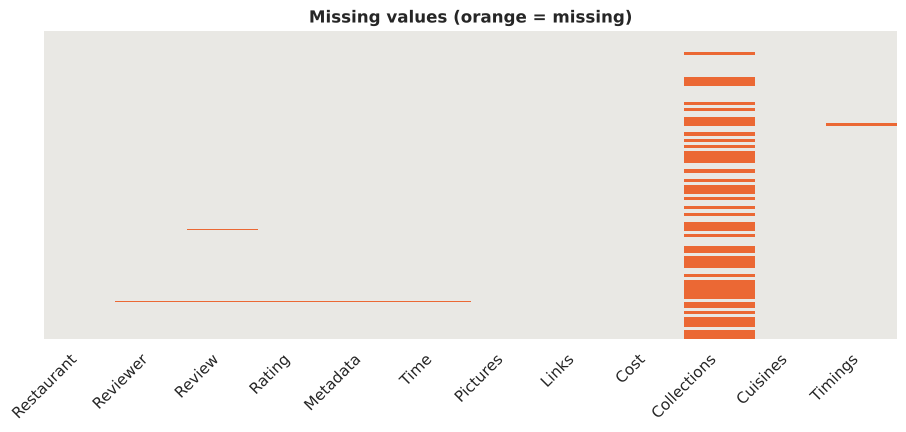

In [9]:
# Visualizing the missing values
plt.figure(figsize=(11, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap=[ '#e9e8e4', ORANGE])
plt.title('Missing values (orange = missing)')
plt.xticks(rotation=45, ha='right')
plt.show()

### What did you know about your dataset?

* The two files are linked by restaurant name: 105 restaurants in the metadata file, and 100 of them have reviews (exactly 100 reviews each, 10,000 in total). The merge matched every review, giving a 10,000 x 12 dataset.
* **Duplicates:** 36 duplicate rows. **Missing values:** 38 reviews are completely empty records, 7 more have a rating but no text, `Collections` is missing for half the rows (restaurants with no Zomato collection) and `Timings` is missing for one restaurant.
* **Data quality issues:** `Cost` was text with thousands separators, `Rating` was text because of one stray value ("Like"), and reviewer activity was packed into a single `Metadata` string.
* Reviews span **31 May 2016 to 25 May 2019**, but about 97% were written in 2018-2019, because the file holds each restaurant's latest 100 reviews.
* Ratings are polarised: 38.5% are 5 stars, 23.8% 4 stars, 12% 3 stars, 6.9% 2 stars and 17.4% 1 star.

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
print(list(df.columns))

['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']


In [11]:
# Dataset Describe
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Restaurant,10000,100,Beyond Flavours,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reviewer,9962,7446,Ankita,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review,9955,9364,good,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9962,10,5,3832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Metadata,9962,2477,1 Review,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9962,9782,5/5/2019 22:39,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pictures,10000.0,NaN,NaN,NaN,0.7486,2.570381,0.0,0.0,0.0,0.0,64.0
Links,10000,100,https://www.zomato.com/hyderabad/beyond-flavou...,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cost,10000.0,NaN,NaN,NaN,872.0,503.429582,150.0,500.0,700.0,1200.0,2800.0
Collections,5000,42,Food Hygiene Rated Restaurants in Hyderabad,400,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description

| Variable | Description |
|---|---|
| **Restaurant** | Name of the restaurant (join key with the metadata file) |
| **Reviewer** | Name of the reviewer |
| **Review** | Free-text review (used for sentiment analysis) |
| **Rating** | Rating given by the reviewer, 1 to 5 (half-stars exist) |
| **Metadata** | Reviewer activity, e.g. "3 Reviews, 2 Followers" (parsed into `Reviewer_Reviews` and `Followers`) |
| **Time** | Timestamp of the review |
| **Pictures** | Number of pictures attached to the review |
| **Links** | Zomato page of the restaurant |
| **Cost** | Approximate cost for two people (₹) |
| **Collections** | Zomato curated lists the restaurant belongs to (e.g. "Great Buffets", "Top-Rated") |
| **Cuisines** | Cuisines served (comma separated) |
| **Timings** | Opening hours |

**Created features:** `Year`, `Month`, `Hour`, `Day_Of_Week`, `Reviewer_Reviews`, `Followers`, `Review_Length`, `Cuisine_Count`, `Has_Collection`, `Has_Picture`, `Cost_Tier`, `Rating_Band`, plus the cleaned text `clean_review`.

### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
pd.DataFrame({'Unique values': df.nunique(), 'Data type': df.dtypes.astype(str)})

,Unique values,Data type
Restaurant,100,str
Reviewer,7446,str
Review,9364,str
Rating,10,str
Metadata,2477,str
Time,9782,str
Pictures,36,int64
Links,100,str
Cost,28,int64
Collections,42,str


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# Write your code to make your dataset analysis ready.
rows_start = len(df)

# 1. Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# 2. Rating is text because of one stray value ("Like") -> convert to number (bad value becomes NaN)
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')

# 3. Time -> datetime, then calendar features
df['Time'] = pd.to_datetime(df['Time'], errors='coerce')
df['Year'] = df['Time'].dt.year
df['Month'] = df['Time'].dt.month
df['Hour'] = df['Time'].dt.hour
df['Day_Of_Week'] = df['Time'].dt.day_name()

# 4. Reviewer metadata ("3 Reviews , 2 Followers") -> two numeric columns
reviewer_reviews = df['Metadata'].str.extract(r'(\d+)\s*Review')[0].astype(float)
followers = df['Metadata'].str.extract(r'(\d+)\s*Follower')[0].astype(float)
df['Reviewer_Reviews'] = reviewer_reviews
df['Followers'] = followers.where(df['Metadata'].isna(), followers.fillna(0))   # no "Followers" text = 0 followers

# 5. Drop records that carry no review information at all (no reviewer, text or rating)
df = df.dropna(subset=['Reviewer', 'Review', 'Rating'], how='all').reset_index(drop=True)

# 6. Derived features
df['Review_Length'] = df['Review'].fillna('').str.split().str.len()                 # words per review
df['Cuisine_Count'] = df['Cuisines'].str.split(',').str.len()                       # cuisines served
df['Has_Collection'] = df['Collections'].notna().astype(int)                        # listed in a Zomato collection?
df['Has_Picture'] = (df['Pictures'] > 0).astype(int)
df['Cost_Tier'] = pd.cut(df['Cost'], bins=[0, 500, 1000, np.inf],
                         labels=['Budget (≤500)', 'Mid (501-1000)', 'Premium (>1000)'])
df['Rating_Band'] = pd.cut(df['Rating'], bins=[0, 2.5, 3.5, 5],
                           labels=['Negative (≤2.5)', 'Neutral (3-3.5)', 'Positive (≥4)'])

# 7. Restaurant-level summary table (used by several charts and by clustering later)
rest_stats = (df.assign(Positive=(df['Rating'] >= 4).astype(int))
                .groupby('Restaurant')
                .agg(Avg_Rating=('Rating', 'mean'), Pct_Positive=('Positive', 'mean'),
                     Cost=('Cost', 'first'), Reviews=('Rating', 'size'))
                .reset_index())

print(f'Rows: {rows_start:,} -> {len(df):,}  (duplicates and empty records removed)')
print('Date range:', df['Time'].min().date(), 'to', df['Time'].max().date())
print('Restaurants with reviews:', df['Restaurant'].nunique())
df.head(3)

Rows: 10,000 -> 9,962  (duplicates and empty records removed)
Date range: 2016-05-31 to 2019-05-25
Restaurants with reviews: 100


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Links,Cost,Collections,...,Hour,Day_Of_Week,Reviewer_Reviews,Followers,Review_Length,Cuisine_Count,Has_Collection,Has_Picture,Cost_Tier,Rating_Band
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5.0,"1 Review , 2 Followers",2019-05-25 15:54:00,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...",...,15.0,Saturday,1.0,2.0,41,6,1,0,Mid (501-1000),Positive (≥4)
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5.0,"3 Reviews , 2 Followers",2019-05-25 14:20:00,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...",...,14.0,Saturday,3.0,2.0,27,6,1,0,Mid (501-1000),Positive (≥4)
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5.0,"2 Reviews , 3 Followers",2019-05-24 22:54:00,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...",...,22.0,Friday,2.0,3.0,31,6,1,0,Mid (501-1000),Positive (≥4)


### What all manipulations have you done and insights you found?

**Manipulations:** removed duplicates and empty records (10,000 to 9,962 rows); converted `Cost` and `Rating` to numbers; parsed `Time` into a datetime plus year, month, hour and weekday; parsed `Metadata` into reviewer review count and followers (no "Followers" text means 0); created review length, cuisine count, collection flag, picture flag, a three-level cost tier (Budget up to ₹500, Mid ₹501-1,000, Premium above ₹1,000) and a rating band (Negative up to 2.5, Neutral 3-3.5, Positive 4 and above); built a restaurant-level summary table.

**Insights found:** reviews are heavily concentrated in 2018-2019; the average rating is 3.60; the median restaurant costs ₹700 for two; and reviewer activity is very skewed (a few reviewers have thousands of followers), which is why those columns are later capped and log-transformed.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

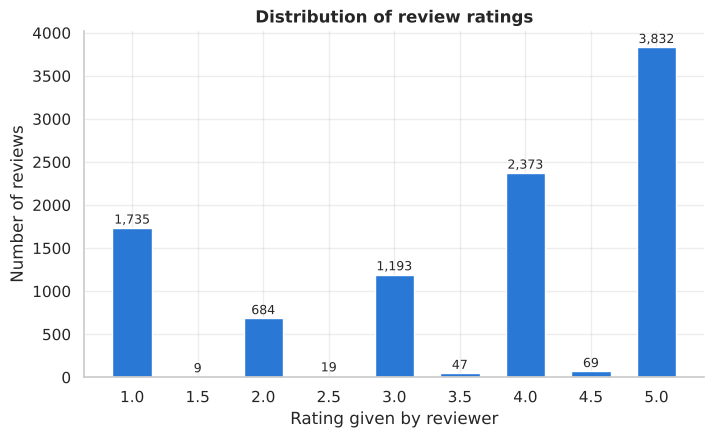

In [14]:
# Chart - 1 visualization code  (Univariate: rating distribution)
counts = df['Rating'].value_counts().sort_index()
labels = counts.index.astype(str)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(labels, counts.values, color=BLUE, width=0.6)
for x, v in zip(labels, counts.values):
    ax.text(x, v + 50, f'{v:,}', ha='center', fontsize=9)
ax.set(title='Distribution of review ratings', xlabel='Rating given by reviewer', ylabel='Number of reviews')
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of counts is the simplest way to see how a discrete variable such as rating is distributed, which is the starting point for every sentiment question.

##### 2. What is/are the insight(s) found from the chart?

Ratings are polarised, not bell-shaped: 5 stars is the most common rating (38.5%), 4 stars follows (23.8%), but 1 star is the second-largest single value (17.4%) and 2 stars is rare (6.9%). The mean is 3.60. Half-star ratings are almost absent.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** about 63% of reviews are 4 or 5 stars, so the platform has a strong base of happy customers to showcase. **Negative:** the large block of 1-star reviews (17.4%) means a sizeable group had a really bad experience, and such reviews hurt conversion and brand trust. Averages alone hide this split, so complaint monitoring is needed.

#### Chart - 2

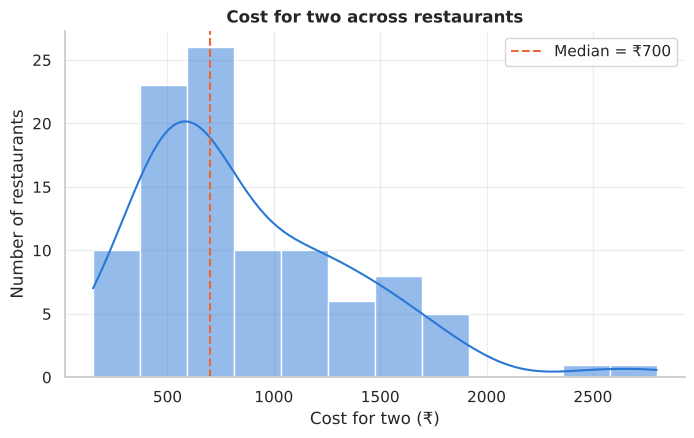

In [15]:
# Chart - 2 visualization code  (Univariate: cost for two)
rest = df.drop_duplicates('Restaurant')            # one row per restaurant
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(rest['Cost'], bins=12, kde=True, color=BLUE, ax=ax)
ax.axvline(rest['Cost'].median(), color=ORANGE, ls='--', label=f"Median = ₹{rest['Cost'].median():,.0f}")
ax.set(title='Cost for two across restaurants', xlabel='Cost for two (₹)', ylabel='Number of restaurants')
ax.legend()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram with a density curve shows the shape of the price distribution and where most restaurants sit, which a table of statistics cannot show as quickly.

##### 2. What is/are the insight(s) found from the chart?

Prices are right-skewed. The median cost for two is ₹700 (mean ₹872), three quarters of restaurants cost ₹1,200 or less, and a few luxury hotel restaurants reach ₹2,800. The cheapest costs ₹150.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the market is centred on affordable and mid-range dining, so promotions and bundles priced around ₹500-1,200 reach the most customers. **Negative:** there are few premium venues, so the premium end offers limited choice, but also less competition for a restaurant that positions itself there well.

#### Chart - 3

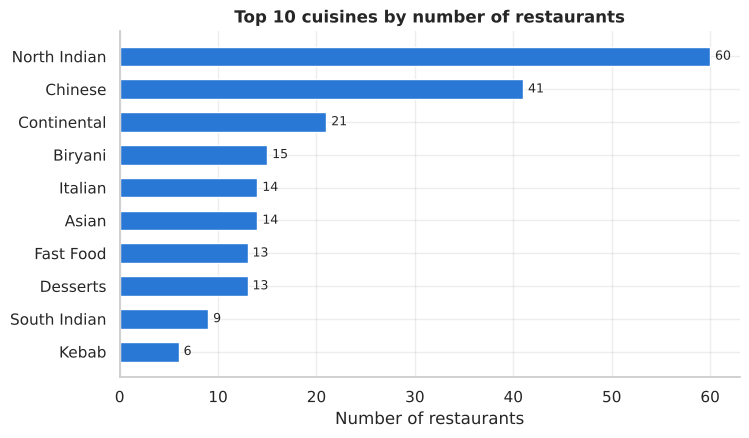

In [16]:
# Chart - 3 visualization code  (Univariate: most common cuisines)
cuisine_counts = rest['Cuisines'].str.split(', ').explode().value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(cuisine_counts.index, cuisine_counts.values, color=BLUE, height=0.6)
for y, v in enumerate(cuisine_counts.values):
    ax.text(v + 0.5, y, str(v), va='center', fontsize=9)
ax.set(title='Top 10 cuisines by number of restaurants', xlabel='Number of restaurants')
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart ranks categories and keeps long cuisine names readable, so it suits a top-10 comparison.

##### 2. What is/are the insight(s) found from the chart?

North Indian (60 restaurants) and Chinese (41) dominate the menu offering, followed by Continental (21), Biryani (15) and Asian, Italian, Fast Food and Desserts at 13-14 each. Many restaurants list several cuisines at once.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** knowing the most common cuisines shows what customers can easily find, and where gaps (for example regional or Mediterranean cuisines) leave room for new restaurants. **Negative:** North Indian and Chinese are saturated, so a new restaurant in those categories must win on service or price because it cannot win on novelty.

#### Chart - 4

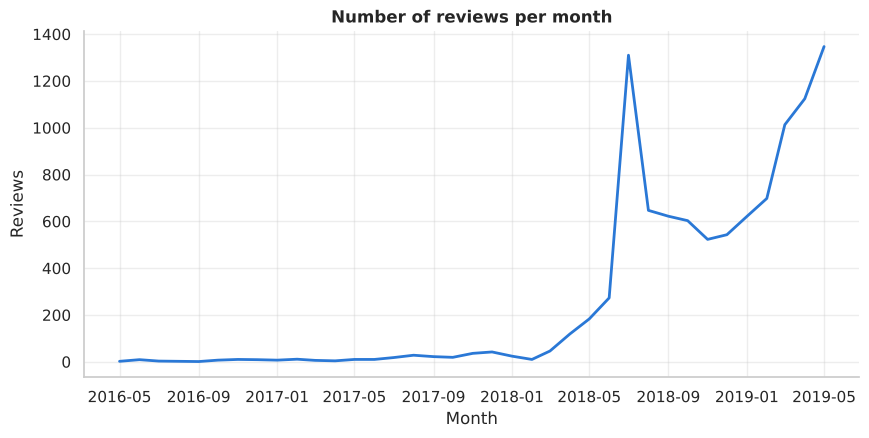

Share of reviews written in 2019: 48%


In [17]:
# Chart - 4 visualization code  (Univariate: review volume over time)
monthly = df['Time'].dt.to_period('M').value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly.index.to_timestamp(), monthly.values, color=BLUE, lw=2)
ax.set(title='Number of reviews per month', xlabel='Month', ylabel='Reviews')
plt.show()
print('Share of reviews written in 2019:', f"{(df['Year'] == 2019).mean():.0%}")

##### 1. Why did you pick the specific chart?

A line chart over months is the natural way to show how review activity changes over time.

##### 2. What is/are the insight(s) found from the chart?

Review volume was tiny until 2017 (43 reviews in 2016 and 213 in 2017) and then jumped to 4,903 in 2018 and 4,803 in 2019, with 2019 covering only about five months. 48% of all reviews come from 2019. Because the file keeps each restaurant's most recent 100 reviews, the curve mainly reflects that sampling.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** recent activity is high, so the analysis reflects current customer opinion rather than outdated feedback. **Negative:** the early period has too little data to study long-term trends, so the 2016-2017 ratings should not be used for conclusions about growth.

#### Chart - 5

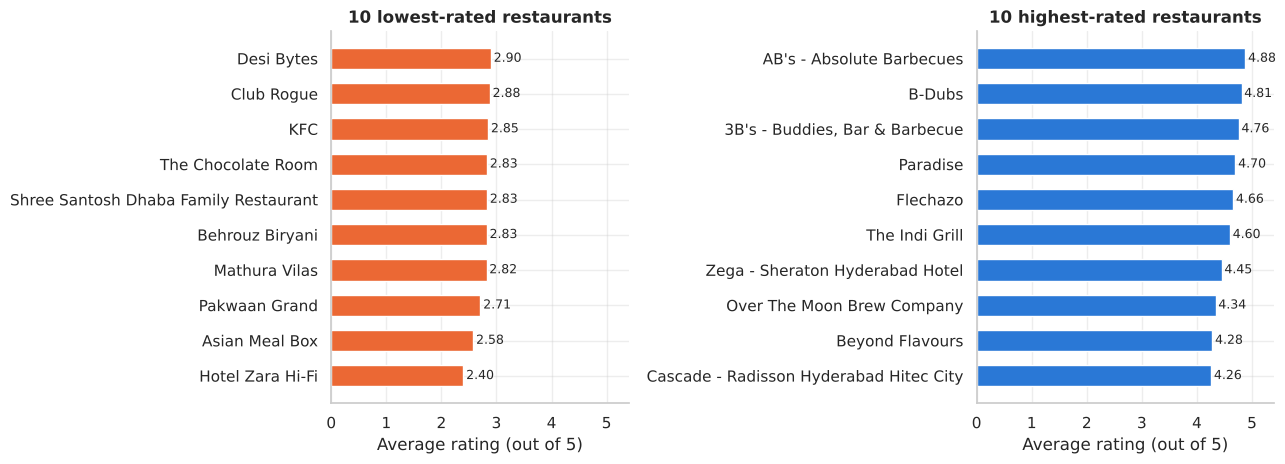

In [18]:
# Chart - 5 visualization code  (Bivariate: restaurant vs average rating)
avg = rest_stats.set_index('Restaurant')['Avg_Rating'].sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
for ax, data, color, title in [(axes[0], avg.head(10), ORANGE, '10 lowest-rated restaurants'),
                               (axes[1], avg.tail(10), BLUE, '10 highest-rated restaurants')]:
    ax.barh(data.index, data.values, color=color, height=0.6)
    for y, v in enumerate(data.values):
        ax.text(v + 0.05, y, f'{v:.2f}', va='center', fontsize=9)
    ax.set(title=title, xlim=(0, 5.4), xlabel='Average rating (out of 5)')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Two side-by-side horizontal bar charts rank the best and the worst restaurants on the same scale, which makes the gap between them easy to see.

##### 2. What is/are the insight(s) found from the chart?

The best restaurants are AB's - Absolute Barbecues (4.88), B-Dubs (4.81), 3B's - Buddies, Bar & Barbecue (4.76), Paradise (4.70) and Flechazo (4.66). The lowest are Hotel Zara Hi-Fi (2.40), Asian Meal Box (2.58), Pakwaan Grand (2.71), Mathura Vilas (2.82) and Behrouz Biryani (2.82). The gap between best and worst is almost 2.5 rating points.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the winners (several are barbecue or buffet concepts) are clear benchmarks for what customers value, and Zomato can feature them. **Negative:** the bottom restaurants risk losing customers and should be offered improvement support or visibility penalties; leaving them unaddressed hurts the platform's recommendation quality.

#### Chart - 6

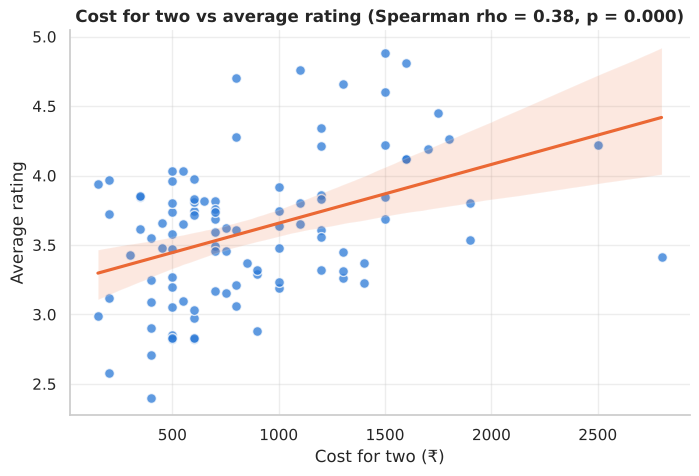

In [19]:
# Chart - 6 visualization code  (Bivariate numeric-numeric: cost vs average rating)
rho, p = stats.spearmanr(rest_stats['Cost'], rest_stats['Avg_Rating'])
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=rest_stats, x='Cost', y='Avg_Rating', ax=ax,
            scatter_kws={'color': BLUE, 'alpha': 0.75, 'edgecolor': 'white', 's': 50},
            line_kws={'color': ORANGE})
ax.set(title=f'Cost for two vs average rating (Spearman rho = {rho:.2f}, p = {p:.3f})',
       xlabel='Cost for two (₹)', ylabel='Average rating')
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot with a regression line is the standard way to examine the relationship between two numeric variables, here price and average rating, one point per restaurant.

##### 2. What is/are the insight(s) found from the chart?

There is a moderate positive relationship (Spearman rho = 0.38, p < 0.001): more expensive restaurants tend to be rated higher. The points are widely spread, though, so price explains only part of the rating: mid-priced Paradise (₹800, 4.70) do very well, while some inexpensive places score below 3.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** customers accept higher prices for a better experience, so quality-focused pricing is viable. **Negative:** price alone does not guarantee satisfaction, and a restaurant that raises prices without improving food and service is likely to see poor ratings.

#### Chart - 7

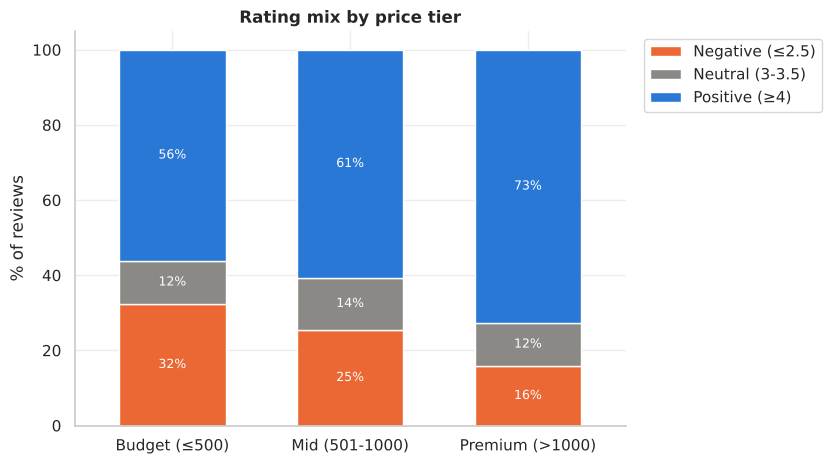

In [20]:
# Chart - 7 visualization code  (Bivariate categorical-categorical: cost tier vs rating band)
share = pd.crosstab(df['Cost_Tier'], df['Rating_Band'], normalize='index') * 100
ax = share.plot(kind='bar', stacked=True, color=[ORANGE, GREY, BLUE], figsize=(8.5, 4.8), width=0.6, edgecolor='white')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', label_type='center', color='white', fontsize=9)
ax.set(title='Rating mix by price tier', xlabel='', ylabel='% of reviews')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A 100% stacked bar compares two categorical variables (price tier and rating band) while removing the effect of the different number of reviews in each tier.

##### 2. What is/are the insight(s) found from the chart?

Satisfaction rises with price: positive reviews make up 56% of Budget, 61% of Mid and 73% of Premium reviews, while negative reviews fall from 32% (Budget) to 25% (Mid) to 16% (Premium). The average rating goes from 3.36 to 3.52 to 3.95.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** premium restaurants deliver the most consistent satisfaction, which supports premium positioning and targeted offers. **Negative:** one in three budget-tier reviews is negative, so budget restaurants (the largest group) carry the most risk of churn and need quality and service improvements first.

#### Chart - 8

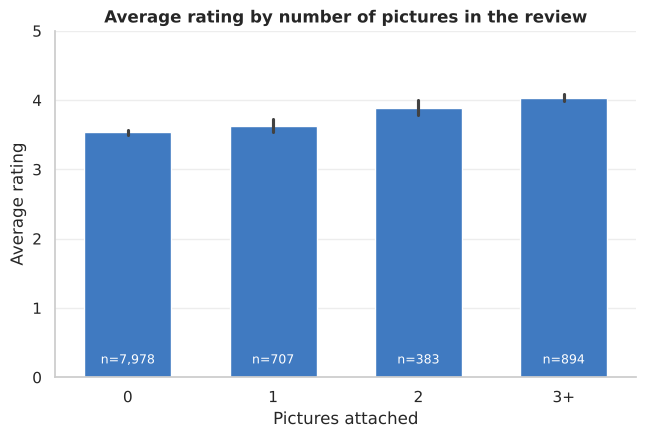

In [21]:
# Chart - 8 visualization code  (Bivariate numeric-categorical: pictures vs rating)
pic_group = df['Pictures'].clip(upper=3).map({0: '0', 1: '1', 2: '2', 3: '3+'})
order = ['0', '1', '2', '3+']
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.barplot(x=pic_group, y=df['Rating'], order=order, color=BLUE, errorbar=('ci', 95), ax=ax, width=0.6)
ax.set(title='Average rating by number of pictures in the review', xlabel='Pictures attached', ylabel='Average rating', ylim=(0, 5))
for i, g in enumerate(order):
    ax.text(i, 0.2, f'n={int((pic_group == g).sum()):,}', ha='center', color='white', fontsize=9)
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of mean rating with confidence intervals compares a numeric outcome across groups of a count variable (pictures), and shows whether the differences are reliable.

##### 2. What is/are the insight(s) found from the chart?

Ratings rise steadily with the number of pictures: 3.54 with none, 3.63 with one, 3.89 with two and 4.04 with three or more. 80% of reviews have no picture, so photo reviews are rare.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** people who bother to upload photos are usually happy, so encouraging photo uploads (badges, rewards) increases helpful content and positive visibility. **Negative:** photo reviews are skewed positive, so average ratings built mostly from them could overstate quality; Zomato should not rely on them alone.

#### Chart - 9

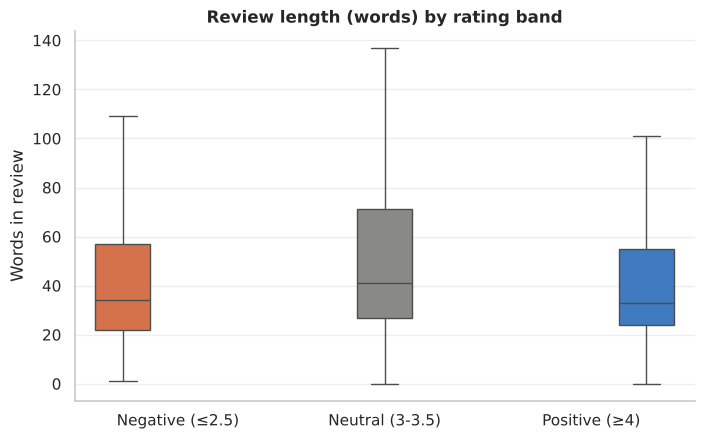

Rating_Band
Negative (≤2.5)    34.0
Neutral (3-3.5)    41.0
Positive (≥4)      33.0
Name: Median words, dtype: float64


In [22]:
# Chart - 9 visualization code  (Bivariate: review length vs rating band)
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.boxplot(data=df.dropna(subset=['Rating_Band']), x='Rating_Band', y='Review_Length', hue='Rating_Band',
            palette=[ORANGE, GREY, BLUE], showfliers=False, legend=False, ax=ax)
ax.set(title='Review length (words) by rating band', xlabel='', ylabel='Words in review')
plt.show()
print(df.groupby('Rating_Band', observed=True)['Review_Length'].median().rename('Median words'))

##### 1. Why did you pick the specific chart?

A box plot shows the median and spread of review length for each rating band, so we can test whether unhappy or happy customers write more.

##### 2. What is/are the insight(s) found from the chart?

The median review length is almost identical across bands (34 words for negative, 41 for neutral, 33 for positive), though the spread is wide. Length therefore says little about sentiment (Spearman rho with rating is only -0.14).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it confirms that the *words* matter, not the length, which supports building the sentiment model on text content. **Negative:** no shortcut is available: simply counting long reviews will not find unhappy customers.

#### Chart - 10

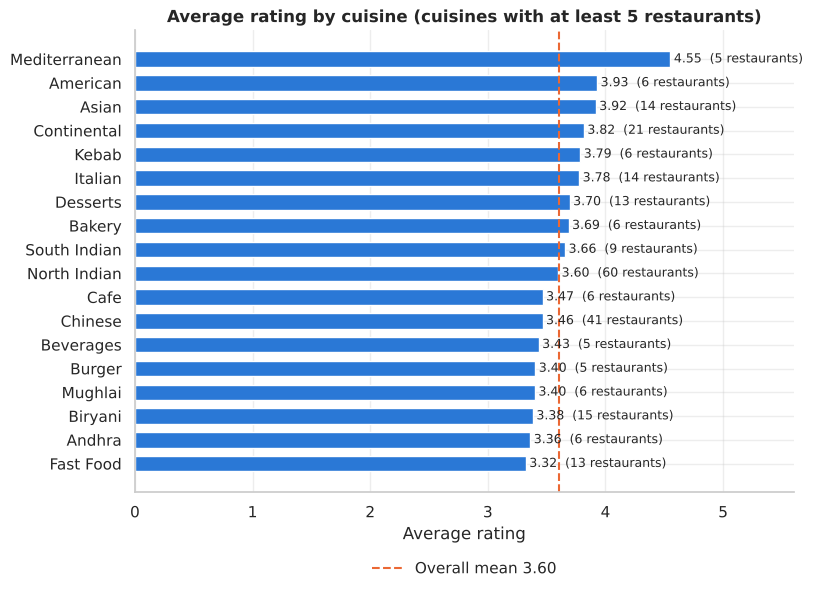

In [23]:
# Chart - 10 visualization code  (Bivariate: cuisine vs average rating)
cuisine_df = df.assign(Cuisine=df['Cuisines'].str.split(', ')).explode('Cuisine')
cuisine_stats = (cuisine_df.groupby('Cuisine')
                 .agg(Avg_Rating=('Rating', 'mean'), Restaurants=('Restaurant', 'nunique'))
                 .query('Restaurants >= 5').sort_values('Avg_Rating'))
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(cuisine_stats.index, cuisine_stats['Avg_Rating'], color=BLUE, height=0.65)
for y, (r, n) in enumerate(zip(cuisine_stats['Avg_Rating'], cuisine_stats['Restaurants'])):
    ax.text(r + 0.03, y, f'{r:.2f}  ({n} restaurants)', va='center', fontsize=9)
ax.axvline(df['Rating'].mean(), color=ORANGE, ls='--', label=f"Overall mean {df['Rating'].mean():.2f}")
ax.set(title='Average rating by cuisine (cuisines with at least 5 restaurants)', xlim=(0, 5.6), xlabel='Average rating')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.show()

##### 1. Why did you pick the specific chart?

A ranked horizontal bar chart compares average rating across many categories, with the overall mean as a reference line, to show which cuisines outperform.

##### 2. What is/are the insight(s) found from the chart?

Mediterranean restaurants have the highest average rating (4.55, 5 restaurants), followed by American (3.93), Asian (3.92) and Continental (3.82). Fast Food (3.32), Andhra (3.36), Biryani (3.38) and Mughlai (3.40) are below the overall mean of 3.60; Chinese (3.46) and North Indian (3.60) are at or below it despite being the most common cuisines.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** cuisines such as Mediterranean, Asian and Continental can be promoted as premium discovery options. **Negative:** Biryani and Fast Food are popular but the least satisfying; the biryani category has 15 restaurants and a rating of 3.38, which points to consistency or delivery problems that cost the most customers.

#### Chart - 11

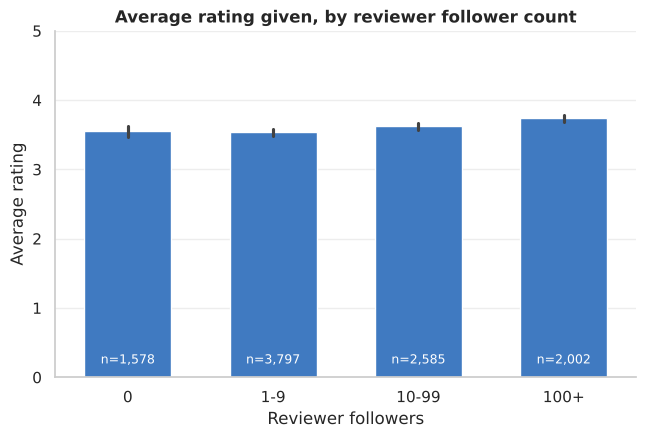

In [24]:
# Chart - 11 visualization code  (Bivariate: reviewer popularity vs rating)
follower_group = pd.cut(df['Followers'], bins=[-1, 0, 9, 99, np.inf], labels=['0', '1-9', '10-99', '100+'])
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.barplot(x=follower_group, y=df['Rating'], color=BLUE, errorbar=('ci', 95), ax=ax, width=0.6)
ax.set(title='Average rating given, by reviewer follower count', xlabel='Reviewer followers', ylabel='Average rating', ylim=(0, 5))
for i, g in enumerate(['0', '1-9', '10-99', '100+']):
    ax.text(i, 0.2, f'n={int((follower_group == g).sum()):,}', ha='center', color='white', fontsize=9)
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of mean rating by reviewer follower group checks whether more influential reviewers rate differently, which matters for how much weight their reviews deserve.

##### 2. What is/are the insight(s) found from the chart?

More-followed reviewers rate slightly higher: 3.55 for no followers, 3.53 for 1-9, 3.62 for 10-99 and 3.74 for 100 or more followers. The differences are small, and the 100+ group (2,002 reviews) is meaningfully large.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** experienced reviewers are somewhat more positive, so influencer outreach can generate favourable but credible content. **Negative:** new reviewers rate lower, so a restaurant may be judged harshly by first-time users; replying to these reviews quickly can limit the damage.

#### Chart - 12

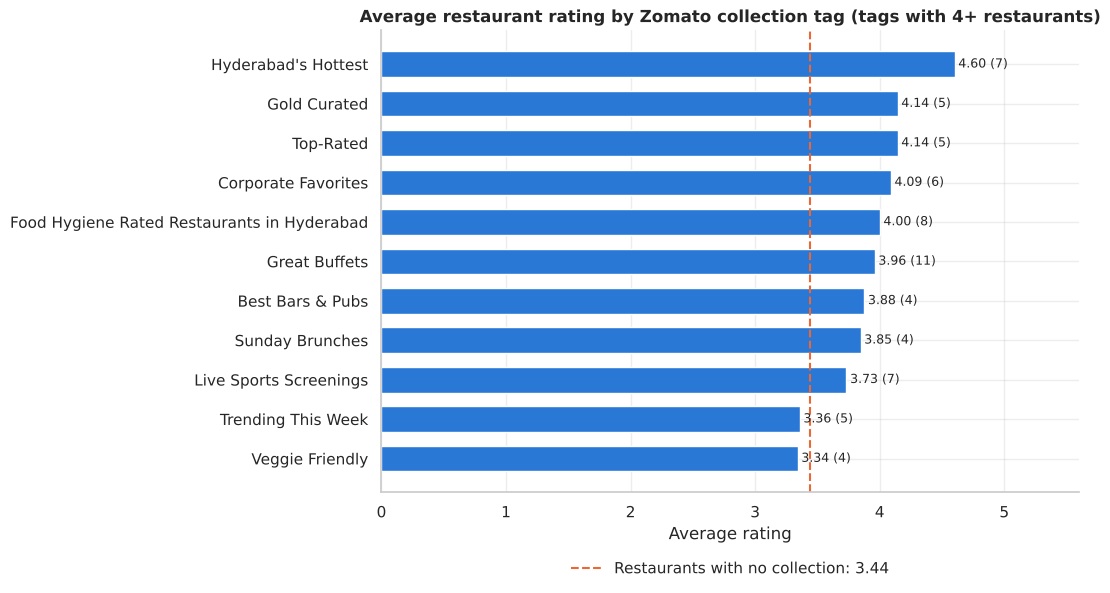

In [25]:
# Chart - 12 visualization code  (Bivariate: Zomato collection tags vs restaurant rating)
tags = rest.assign(Tag=rest['Collections'].str.split(', ')).explode('Tag').dropna(subset=['Tag'])
tag_stats = (tags.merge(rest_stats[['Restaurant', 'Avg_Rating']], on='Restaurant')
             .groupby('Tag').agg(Avg_Rating=('Avg_Rating', 'mean'), Restaurants=('Restaurant', 'nunique'))
             .query('Restaurants >= 4').sort_values('Avg_Rating'))
no_tag_avg = rest_stats.loc[~rest_stats['Restaurant'].isin(tags['Restaurant']), 'Avg_Rating'].mean()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(tag_stats.index, tag_stats['Avg_Rating'], color=BLUE, height=0.65)
for y, (r, n) in enumerate(zip(tag_stats['Avg_Rating'], tag_stats['Restaurants'])):
    ax.text(r + 0.03, y, f'{r:.2f} ({n})', va='center', fontsize=9)
ax.axvline(no_tag_avg, color=ORANGE, ls='--', label=f'Restaurants with no collection: {no_tag_avg:.2f}')
ax.set(title='Average restaurant rating by Zomato collection tag (tags with 4+ restaurants)', xlim=(0, 5.6), xlabel='Average rating')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.show()

##### 1. Why did you pick the specific chart?

A ranked bar chart of average restaurant rating per Zomato collection tag, with the no-collection average as a reference line, shows whether curated lists mark better restaurants.

##### 2. What is/are the insight(s) found from the chart?

Restaurants with at least one collection average 3.77 against 3.44 for those with none. "Hyderabad's Hottest" (4.60) is the top tag, followed by "Gold Curated" and "Top-Rated" (4.14 each) and "Corporate Favorites" (4.09). "Veggie Friendly" (3.34) and "Trending This Week" (3.36) are below the no-collection average. Some tags such as Top-Rated are partly based on ratings themselves.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** being listed in a quality collection goes with higher satisfaction, so collections are a valuable marketing lever and a good signal for customers. **Negative:** half of the restaurants have no collection at all and are visibly rated lower, and collections like "Veggie Friendly" do not guarantee quality, so listing alone is not a mark of success.

#### Chart - 13

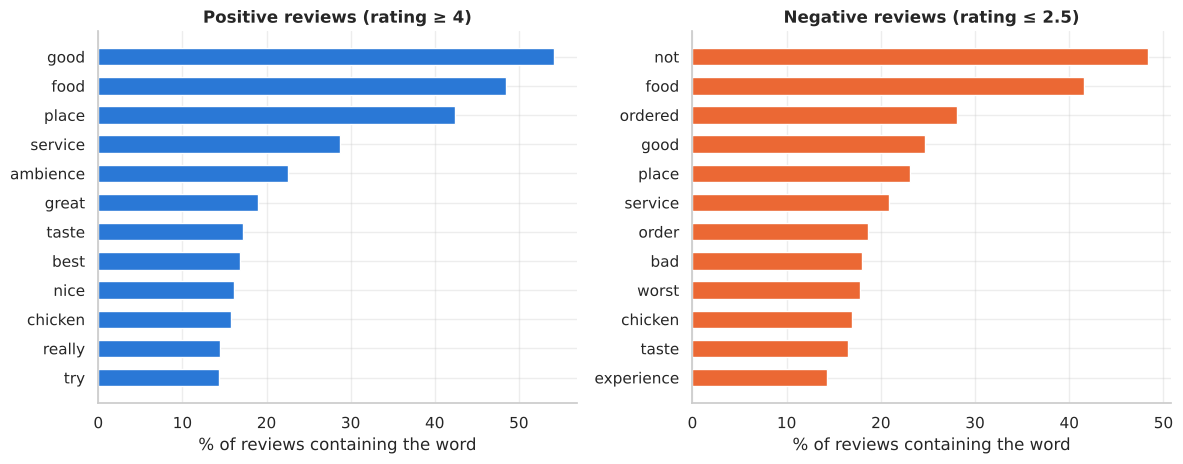

In [26]:
# Chart - 13 visualization code  (Bivariate: words used in positive vs negative reviews)
stop_words = list(set(ENGLISH_STOP_WORDS) - {'not', 'no', 'nor', 'never', 'cannot'})
reviews_text = df.dropna(subset=['Review'])

def top_words(texts, n=12):
    """% of reviews in which each word appears (binary counts, words of 3+ letters)."""
    cv = CountVectorizer(stop_words=stop_words, binary=True, min_df=5, token_pattern=r'(?u)\b[a-z]{3,}\b')
    X = cv.fit_transform(texts.str.lower())
    return pd.Series(np.asarray(X.mean(axis=0)).ravel() * 100, index=cv.get_feature_names_out()).nlargest(n).sort_values()

pos_words = top_words(reviews_text.loc[reviews_text['Rating'] >= 4, 'Review'])
neg_words = top_words(reviews_text.loc[reviews_text['Rating'] <= 2.5, 'Review'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, data, color, title in [(axes[0], pos_words, BLUE, 'Positive reviews (rating ≥ 4)'),
                               (axes[1], neg_words, ORANGE, 'Negative reviews (rating ≤ 2.5)')]:
    ax.barh(data.index, data.values, color=color, height=0.6)
    ax.set(title=title, xlabel='% of reviews containing the word')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Two side-by-side bar charts of the most frequent words in positive and negative reviews show *why* customers are happy or unhappy, which no numeric chart can.

##### 2. What is/are the insight(s) found from the chart?

Positive reviews are full of "good", "service", "ambience", "great", "best" and "nice". Negative reviews are dominated by "not" (about 48% of them) and "bad", "worst" and "experience", plus "ordered" and "order", which hints at order and delivery problems. "Food", "place" and "taste" appear in both, so the surrounding words matter.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** praise centres on ambience and service, which restaurants can emphasise in their marketing. **Negative:** negation ("not good", "not tasty") and order-related complaints are the main pain points; this is also why the text pipeline keeps the word "not" instead of removing it as a stop word.

#### Chart - 14 - Correlation Heatmap

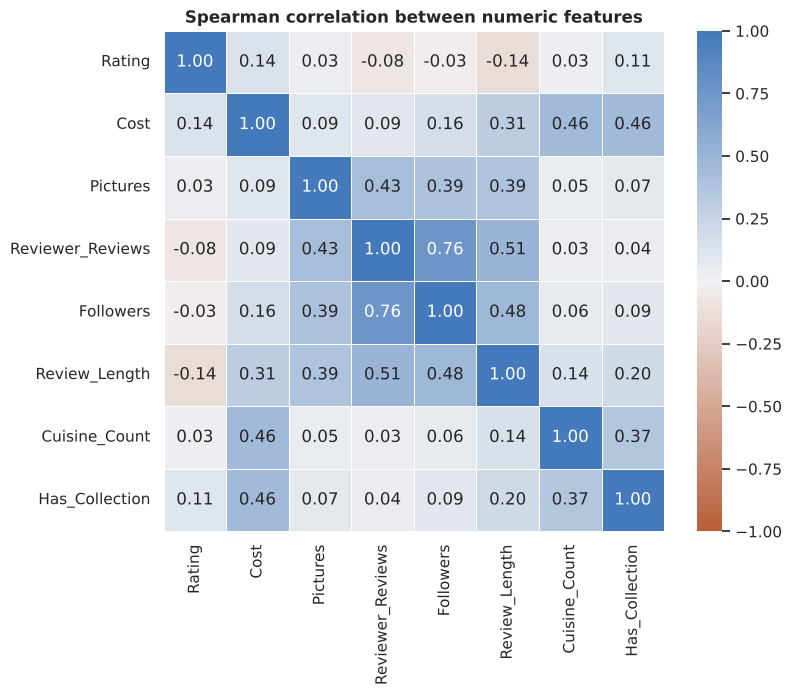

In [27]:
# Correlation Heatmap visualization code
num_cols = ['Rating', 'Cost', 'Pictures', 'Reviewer_Reviews', 'Followers', 'Review_Length', 'Cuisine_Count', 'Has_Collection']
corr = df[num_cols].corr(method='spearman')          # Spearman: several columns are heavily skewed
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', square=True, linewidths=0.5, vmin=-1, vmax=1, center=0,
            cmap=sns.diverging_palette(25, 250, as_cmap=True))
plt.title('Spearman correlation between numeric features')
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap summarises all pairwise relationships between numeric variables at once, which helps spot strong relationships and redundant features before modelling. Spearman correlation is used because several columns are heavily skewed.

##### 2. What is/are the insight(s) found from the chart?

* Rating has only weak correlations with every numeric variable: Cost (+0.14), Has_Collection (+0.11), Review_Length (-0.14). **No single numeric feature predicts rating well, so the review text must carry the signal.**
* The strongest relationship is Reviewer_Reviews with Followers (0.76): active reviewers have more followers. Cost is moderately related to Cuisine_Count (0.46) and Has_Collection (0.46): pricier restaurants offer more cuisines and are more often featured in collections.
* Review_Length goes with Pictures (0.39) and reviewer activity (0.5), so experienced reviewers write longer reviews with photos.

#### Chart - 15 - Pair Plot

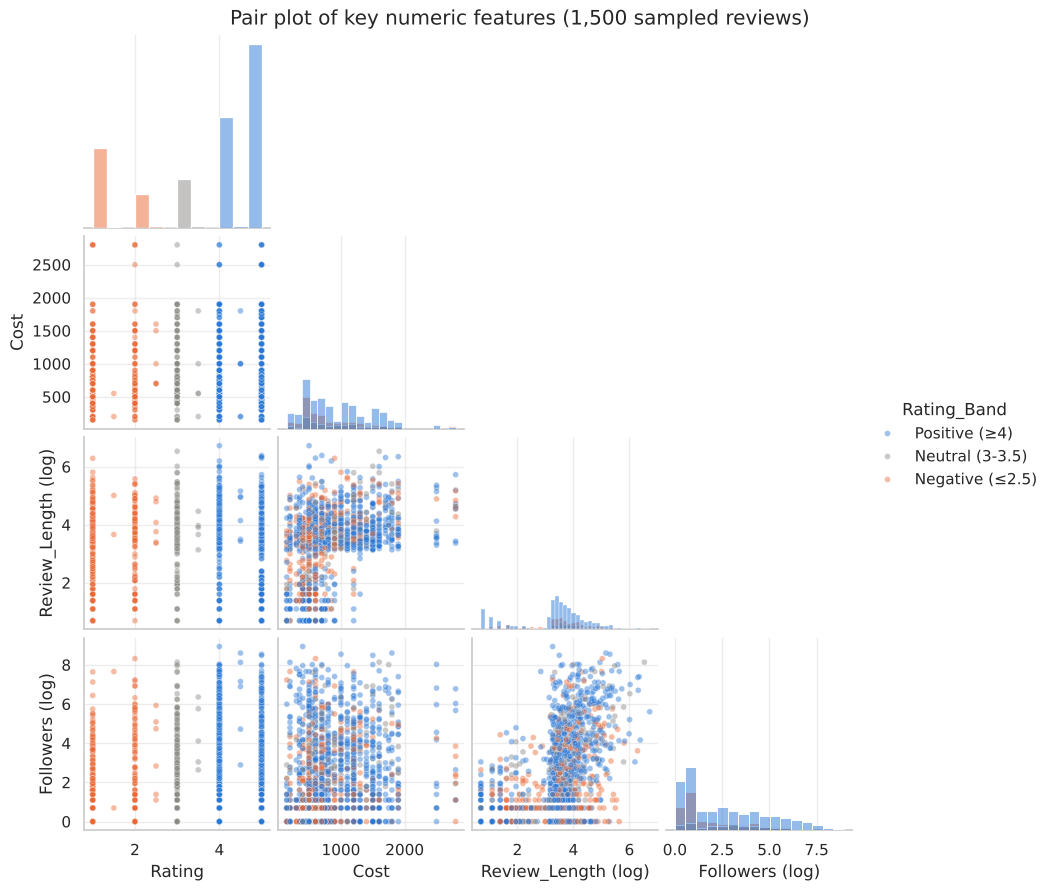

In [28]:
# Pair Plot visualization code
sample = df.dropna(subset=['Rating_Band']).sample(1500, random_state=RANDOM_STATE).copy()
sample['Review_Length (log)'] = np.log1p(sample['Review_Length'])      # log scale for skewed columns
sample['Followers (log)'] = np.log1p(sample['Followers'])
sample['Rating_Band'] = sample['Rating_Band'].astype(str)
g = sns.pairplot(sample[['Rating', 'Cost', 'Review_Length (log)', 'Followers (log)', 'Rating_Band']],
                 hue='Rating_Band', corner=True, diag_kind='hist',
                 palette={'Negative (≤2.5)': ORANGE, 'Neutral (3-3.5)': GREY, 'Positive (≥4)': BLUE},
                 plot_kws={'alpha': 0.45, 's': 18}, height=2.2)
g.figure.suptitle('Pair plot of key numeric features (1,500 sampled reviews)', y=1.01)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every scatter plot and distribution of the key numeric features in one view, coloured by rating band, so we can see both relationships and class separation at the same time. Skewed columns are shown on a log scale.

##### 2. What is/are the insight(s) found from the chart?

* None of the numeric pairs separates the three rating bands: orange, grey and blue points are mixed in every scatter plot. This confirms the heatmap: numeric features alone cannot classify sentiment.
* Followers and Review_Length are right-skewed, and become far more symmetric on a log scale, which justifies the log transform used later.
* Reviews that are very short (log length below 2) are mostly from reviewers with few followers, a sign of low-effort reviews.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on the charts, three statements are tested at a 5% significance level:
1. **H1:** restaurants that cost more than the median (₹700 for two) receive higher ratings (Charts 6 and 7).
2. **H2:** reviews that include pictures give higher ratings than reviews without pictures (Chart 8).
3. **H3:** a restaurant being listed in a Zomato collection is associated with the rating band its reviews fall into (Chart 12).

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** The ratings in higher-cost restaurants (cost above ₹700) are not higher than in lower-cost restaurants.
**H1:** Ratings in higher-cost restaurants are higher.

**Result:** mean rating 3.79 (higher cost) against 3.42 (lower cost); Mann-Whitney U = 13,956,742; p-value = 5.7 x 10^-30 < 0.05, so **we reject H0**: higher-cost restaurants are rated significantly higher.

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value  (H1: higher-cost restaurants vs the rest)
ALPHA = 0.05
median_cost = df['Cost'].median()
high_cost = df.loc[df['Cost'] > median_cost, 'Rating'].dropna()
low_cost = df.loc[df['Cost'] <= median_cost, 'Rating'].dropna()
u_stat, p_value = stats.mannwhitneyu(high_cost, low_cost, alternative='greater')
print(f'Median cost split at ₹{median_cost:.0f}')
print(f'Mean rating  - higher cost: {high_cost.mean():.2f} (n={len(high_cost):,}) | lower cost: {low_cost.mean():.2f} (n={len(low_cost):,})')
print(f'Mann-Whitney U = {u_stat:,.0f}, p-value = {p_value:.3g}')
print('Decision:', 'Reject H0' if p_value < ALPHA else 'Fail to reject H0')

Median cost split at ₹700
Mean rating  - higher cost: 3.79 (n=4,885) | lower cost: 3.42 (n=5,076)
Mann-Whitney U = 13,956,742, p-value = 5.71e-30
Decision: Reject H0


##### Which statistical test have you done to obtain P-Value?

**Mann-Whitney U test** (one-sided, alternative = greater).

##### Why did you choose the specific statistical test?

Ratings are ordinal (1-5 stars) and clearly not normally distributed (Chart 1), so a rank-based test that does not assume normality is more appropriate than a t-test. The two groups are independent, and the one-sided alternative matches the question of whether higher-cost restaurants are rated higher.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** The mean rating of reviews with pictures is not higher than that of reviews without pictures.
**H1:** The mean rating of reviews with pictures is higher.

**Result:** mean 3.86 (with pictures, n = 1,983) against 3.54 (without, n = 7,978); Welch t = 10.98; p-value = 5.5 x 10^-28 < 0.05, so **we reject H0**: reviews with pictures rate significantly higher.

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value  (H2: reviews with pictures vs without)
with_pic = df.loc[df['Pictures'] > 0, 'Rating'].dropna()
without_pic = df.loc[df['Pictures'] == 0, 'Rating'].dropna()
t_stat, p_value = stats.ttest_ind(with_pic, without_pic, equal_var=False, alternative='greater')   # Welch t-test
print(f'Mean rating - with pictures: {with_pic.mean():.2f} (n={len(with_pic):,}) | without: {without_pic.mean():.2f} (n={len(without_pic):,})')
print(f'Welch t = {t_stat:.2f}, p-value = {p_value:.3g}')
print('Decision:', 'Reject H0' if p_value < ALPHA else 'Fail to reject H0')

Mean rating - with pictures: 3.86 (n=1,983) | without: 3.54 (n=7,978)
Welch t = 10.98, p-value = 5.49e-28
Decision: Reject H0


##### Which statistical test have you done to obtain P-Value?

**Welch's two-sample t-test** (one-sided, unequal variances).

##### Why did you choose the specific statistical test?

We compare the means of two independent groups, and the groups have very different sizes (about 2,000 against 8,000) and may have different variances, so Welch's version (which does not assume equal variances) is the safe choice. With thousands of observations per group, the central limit theorem makes the test of the means reliable even though individual ratings are not normal.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** The rating band (negative / neutral / positive) is independent of whether the restaurant is listed in a Zomato collection.
**H1:** The rating band depends on collection listing.

**Result:** restaurants in a collection get 68% positive and 20% negative reviews, against 58% positive and 29% negative for those without. Chi-square = 122.5, dof = 2, p-value = 2.5 x 10^-27 < 0.05, so **we reject H0**. Cramer's V = 0.11 shows the association is statistically strong but small in size.

#### 2. Perform an appropriate statistical test.

In [31]:
# Perform Statistical Test to obtain P-Value  (H3: collection listing vs rating band)
contingency = pd.crosstab(df['Has_Collection'], df['Rating_Band'])
chi2_stat, p_value, dof, expected = stats.chi2_contingency(contingency)
cramers_v = np.sqrt(chi2_stat / (contingency.values.sum() * (min(contingency.shape) - 1)))
print(contingency, '\n')
print(f'Chi-square = {chi2_stat:.1f}, dof = {dof}, p-value = {p_value:.3g}, Cramer\'s V = {cramers_v:.2f}')
print('Decision:', 'Reject H0' if p_value < ALPHA else 'Fail to reject H0')

Rating_Band     Negative (≤2.5)  Neutral (3-3.5)  Positive (≥4)
Has_Collection                                                 
0                          1430              683           2886
1                          1017              557           3388 

Chi-square = 122.5, dof = 2, p-value = 2.46e-27, Cramer's V = 0.11
Decision: Reject H0


##### Which statistical test have you done to obtain P-Value?

**Chi-square test of independence** (with Cramer's V as effect size).

##### Why did you choose the specific statistical test?

Both variables are categorical (collection listing: yes/no; rating band: three levels), and the question is whether they are related. The chi-square test of independence is the standard test for two categorical variables, and every expected cell count is far above 5, so its assumptions are met.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [32]:
# Handling Missing Values & Missing Value Imputation
print('Missing values before:'); print(df.isnull().sum()[lambda s: s > 0], '\n')

# Rating: the single "Like" entry became NaN -> use that restaurant's median rating
df['Rating'] = df['Rating'].fillna(df.groupby('Restaurant')['Rating'].transform('median'))
df['Rating_Band'] = pd.cut(df['Rating'], bins=[0, 2.5, 3.5, 5], labels=['Negative (≤2.5)', 'Neutral (3-3.5)', 'Positive (≥4)'])

# Text / label columns: explicit "unknown" categories keep the rows without inventing information
df['Review'] = df['Review'].fillna('')
df['Reviewer'] = df['Reviewer'].fillna('Unknown')
df['Collections'] = df['Collections'].fillna('No Collection')
df['Timings'] = df['Timings'].fillna('Not Available')

# Numeric reviewer stats: median (robust to the heavy right tail) if anything is still missing
for col in ['Reviewer_Reviews', 'Followers']:
    df[col] = df[col].fillna(df[col].median())

print('Missing values after:', int(df.isnull().sum().sum()))

Missing values before:
Review                 7
Rating                 1
Collections         5000
Timings              100
Reviewer_Reviews       6
Rating_Band            1
dtype: int64 

Missing values after: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

* **Rating:** the one invalid value ("Like") was filled with the *median rating of that restaurant*: a robust value that does not distort the restaurant's average.
* **Review text:** the 7 missing reviews were set to an empty string (they are dropped before text modelling, because there is nothing to classify). **Reviewer** missing became "Unknown".
* **Collections / Timings:** filled with explicit "No Collection" and "Not Available" labels, because a missing collection is real information (the restaurant is in no collection), not an error.
* **Reviewer numeric stats:** the *median* is used for any remaining gaps, as it is not affected by the heavy right tail.
* The 38 fully empty records had been removed earlier, since they carry no information to impute.

### 2. Handling Outliers

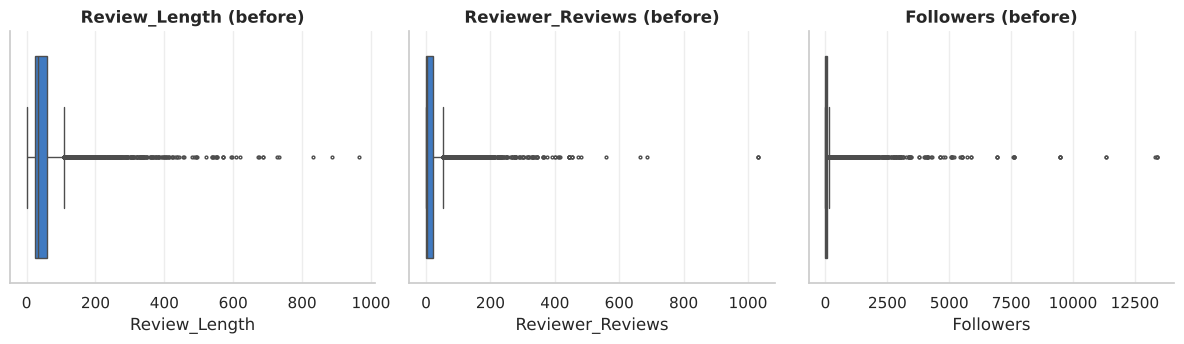

,IQR outliers,Max before,99th percentile,Max after
Review_Length,891,964.0,312.39,312.39
Reviewer_Reviews,1393,1031.0,224.00,224.00
Followers,1578,13410.0,2534.00,2534.00


In [33]:
# Handling Outliers & Outlier treatments
skewed_cols = ['Review_Length', 'Reviewer_Reviews', 'Followers']

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); return int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum())

report = pd.DataFrame({'IQR outliers': [iqr_outliers(df[c]) for c in skewed_cols],
                       'Max before': [df[c].max() for c in skewed_cols],
                       '99th percentile': [df[c].quantile(0.99) for c in skewed_cols]}, index=skewed_cols)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, c in zip(axes, skewed_cols):
    sns.boxplot(x=df[c], color=BLUE, ax=ax, fliersize=2); ax.set_title(f'{c} (before)')
plt.tight_layout(); plt.show()

# Winsorise: cap each skewed column at its 99th percentile (keeps all rows, removes extreme values)
for c in skewed_cols:
    df[c] = df[c].clip(upper=df[c].quantile(0.99))
report['Max after'] = [df[c].max() for c in skewed_cols]
report

##### What all outlier treatment techniques have you used and why did you use those techniques?

* **Technique: winsorising (capping) at the 99th percentile** for `Review_Length`, `Reviewer_Reviews` and `Followers`. These columns are extremely right-skewed (for example one reviewer has 13,410 followers against a typical reviewer with a handful), and 891-1,578 rows per column are flagged by the IQR rule.
* Capping keeps every row (reviews are valuable data and the values are real, not errors) while stopping a few extreme values from dominating the scaled features. `Cost` was not capped: its high values are real luxury restaurants.

### 3. Categorical Encoding

In [34]:
# Encode your categorical columns
# (a) Cost tier -> ordinal code (the order Budget < Mid < Premium is meaningful)
cost_tier_map = {'Budget (≤500)': 0, 'Mid (501-1000)': 1, 'Premium (>1000)': 2}
df['Cost_Tier_Code'] = df['Cost_Tier'].astype(str).map(cost_tier_map)

# (b) Target label for the sentiment model: Positive (rating >= 4) = 1, Negative (rating <= 2.5) = 0.
#     Neutral reviews (3-3.5) are left unlabelled (NaN) and excluded from model training.
df['Sentiment'] = df['Rating_Band'].astype(str).map({'Positive (≥4)': 1, 'Negative (≤2.5)': 0})

# (c) Cuisines (multi-valued) are one-hot encoded with MultiLabelBinarizer later, for restaurant clustering.
print(df['Sentiment'].value_counts(dropna=False).rename({1.0: 'Positive (1)', 0.0: 'Negative (0)'}))

Sentiment
Positive (1)    6275
Negative (0)    2447
NaN             1240
Name: count, dtype: int64


#### What all categorical encoding techniques have you used & why did you use those techniques?

* **Ordinal encoding** for the cost tier (Budget 0 < Mid 1 < Premium 2), because the order is meaningful. (It is later removed as redundant with `Cost`.)
* **Binary label encoding** for the target: Positive = 1, Negative = 0. Neutral reviews (3-3.5 stars) are left unlabelled and excluded from training, which makes the two classes clearly different.
* **Multi-label one-hot encoding** for cuisines (a restaurant serves several), used in the clustering model.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [35]:
# Expand Contraction
CONTRACTIONS = [(r"won't", 'will not'), (r"can't", 'can not'), (r"cannot", 'can not'), (r"n't", ' not'),
                (r"'re", ' are'), (r"'ve", ' have'), (r"'ll", ' will'), (r"'d", ' would'), (r"'m", ' am'), (r"'s", '')]

def expand_contractions(text):
    text = text.replace('’', "'").replace('‘', "'")                 # curly -> straight apostrophes
    for pattern, replacement in CONTRACTIONS:
        text = re.sub(pattern, replacement, text, flags=re.I)
    return text

df['clean_review'] = df['Review'].apply(expand_contractions)
sample_row = df.loc[df['Review'].str.contains("n't", regex=True)].iloc[0]
print('BEFORE:', sample_row['Review'][:150]); print('AFTER :', sample_row['clean_review'][:150])

BEFORE: Short review: Decent breads and starters, bad Shaam Savera, a little screwed up daal makhni (but should be a one-off case)
Better ambience at night...
AFTER : Short review: Decent breads and starters, bad Shaam Savera, a little screwed up daal makhni (but should be a one-off case)
Better ambience at night...


#### 2. Lower Casing

In [36]:
# Lower Casing
df['clean_review'] = df['clean_review'].str.lower()

#### 3. Removing Punctuations

In [37]:
# Remove Punctuations
def remove_urls(text):
    return re.sub(r'https?://\S+|www\.\S+', ' ', text)          # URLs first, so no "https www" fragments are left

def remove_punctuation(text):
    return re.sub(r'[^a-z0-9\s]|_', ' ', text)                  # keeps letters/digits only (also drops emojis)

df['clean_review'] = df['clean_review'].apply(remove_urls).apply(remove_punctuation)

#### 4. Removing URLs & Removing words and digits contain digits.

In [38]:
# Remove URLs & Remove words and digits contain digits
def remove_digit_words(text):
    return re.sub(r'\b\w*\d\w*\b', ' ', text)                   # "5star", "100", "2nd" ...

df['clean_review'] = df['clean_review'].apply(remove_urls).apply(remove_digit_words)

#### 5. Removing Stopwords & Removing White spaces

In [39]:
# Remove Stopwords
# sklearn's list contains negations ("not", "no", "never"...) which carry sentiment -> keep them
STOP_WORDS = set(ENGLISH_STOP_WORDS) - {'not', 'no', 'nor', 'never', 'cannot', 'none', 'nothing', 'without'}

def remove_stopwords(text):
    return ' '.join(w for w in text.split() if w not in STOP_WORDS)

df['clean_review'] = df['clean_review'].apply(remove_stopwords)

In [40]:
# Remove White spaces
def remove_whitespace(text):
    return re.sub(r'\s+', ' ', text).strip()

df['clean_review'] = df['clean_review'].apply(remove_whitespace)

#### 6. Rephrase Text

In [41]:
# Rephrase Text
SLANG = {'gud': 'good', 'nyc': 'nice', 'awsm': 'awesome', 'awsome': 'awesome', 'yumm': 'yum', 'yummy': 'tasty'}

def rephrase(text):
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)                  # "sooooo" -> "soo"
    return ' '.join(SLANG.get(w, w) for w in text.split())

df['clean_review'] = df['clean_review'].apply(rephrase)

#### 7. Tokenization

In [42]:
# Tokenization
df['tokens'] = df['clean_review'].str.split()
df[['Review', 'tokens']].head(3)

,Review,tokens
0,"The ambience was good, food was quite good . h...","[ambience, good, food, quite, good, saturday, ..."
1,Ambience is too good for a pleasant evening. S...,"[ambience, good, pleasant, evening, service, p..."
2,A must try.. great food great ambience. Thnx f...,"[try, great, food, great, ambience, thnx, serv..."


#### 8. Text Normalization

In [43]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
@lru_cache(maxsize=None)
def stem(word):
    return STEMMER.stem(word) if STEMMER else word

def normalize(tokens):
    return [stem(w) for w in tokens]

df['tokens'] = df['tokens'].apply(normalize)
df['clean_review'] = df['tokens'].apply(' '.join)

# One reusable function = the exact same steps, so new reviews at prediction time are cleaned identically
def preprocess_text(text):
    text = expand_contractions(str(text)).lower()
    text = remove_digit_words(remove_punctuation(remove_urls(text)))
    text = rephrase(remove_whitespace(remove_stopwords(text)))
    return ' '.join(normalize(text.split()))

check = df['Review'].sample(300, random_state=RANDOM_STATE)
assert (check.apply(preprocess_text) == df.loc[check.index, 'clean_review']).all()
print('preprocess_text() reproduces the step-by-step cleaning on a 300-review check sample.')
print('\nBEFORE:', df.loc[0, 'Review'][:160]); print('AFTER :', df.loc[0, 'clean_review'][:160])

preprocess_text() reproduces the step-by-step cleaning on a 300-review check sample.

BEFORE: The ambience was good, food was quite good . had Saturday lunch , which was cost effective .
Good place for a sate brunch. One can also chill with friends and o
AFTER : ambienc good food quit good saturday lunch cost effect good place sate brunch chill friend parent waiter soumen das realli courteous help


##### Which text normalization technique have you used and why?

**Stemming (Snowball stemmer).** It reduces related words to a common root ("delicious", "deliciously" become "delici"), which shrinks the vocabulary and groups word forms together. Lemmatization would give more readable words, but it needs a separate WordNet download, which can fail on a fresh machine; the stemmer needs no extra files, so the notebook runs in one go.

#### 9. Part of speech tagging

In [44]:
# POS Taging
# POS tagging needs NLTK's tagger model, which is a separate download. It is tried here and skipped cleanly if
# unavailable - sentiment is carried by the words themselves, so POS tags are not used as model features.
try:
    import nltk
    sample_tokens = df.loc[2, 'Review'].split()[:12]
    print(nltk.pos_tag(sample_tokens))
except Exception as e:
    print('POS tagging skipped (tagger model not available):', type(e).__name__)

POS tagging skipped (tagger model not available): LookupError


#### 10. Text Vectorization

In [45]:
# Vectorizing Text
# Demonstration on the whole corpus to inspect the vocabulary. The model itself fits its TF-IDF on training data only
# (inside the Pipeline), so there is no leakage.
text_rows = df['clean_review'].str.len() > 0
tfidf_demo = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)
X_demo = tfidf_demo.fit_transform(df.loc[text_rows, 'clean_review'])
print('TF-IDF matrix (reviews x terms):', X_demo.shape)
top_terms = pd.Series(np.asarray(X_demo.mean(axis=0)).ravel(), index=tfidf_demo.get_feature_names_out()).nlargest(10)
print('\nTerms with highest average TF-IDF weight:'); print(top_terms.round(3))

TF-IDF matrix (reviews x terms): (9933, 18022)

Terms with highest average TF-IDF weight:
good       0.068
food       0.032
not        0.028
place      0.027
servic     0.022
order      0.021
tast       0.019
nice       0.019
time       0.017
chicken    0.017
dtype: float64


##### Which text vectorization technique have you used and why?

**TF-IDF with unigrams and bigrams** (min_df = 3, max_df = 0.9, sublinear term frequency). TF-IDF down-weights words that appear in almost every review ("food", "place") and boosts distinctive ones. Bigrams capture negations and short phrases such as "not tasty" or "really good", which single words miss. In the models the vectorizer is fitted on training data only, inside the pipeline, to avoid data leakage.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [46]:
# Manipulate Features to minimize feature correlation and create new features
candidate_features = ['Cost', 'Pictures', 'Reviewer_Reviews', 'Followers', 'Review_Length',
                      'Cuisine_Count', 'Has_Collection', 'Cost_Tier_Code']
corr_abs = df[candidate_features].corr(method='spearman').abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
print('Highly correlated pairs (|rho| > 0.8):')
print(upper.stack()[lambda s: s > 0.8].round(2).to_string() or 'none')

# Drop the later column of every highly correlated pair (Cost_Tier_Code is simply a binned copy of Cost)
redundant = [c for c in upper.columns if (upper[c] > 0.8).any()]
BASE_FEATURES = [c for c in candidate_features if c not in redundant]
print('\nDropped as redundant:', redundant)
print('Kept numeric features:', BASE_FEATURES)

Highly correlated pairs (|rho| > 0.8):
Cost  Cost_Tier_Code    0.94

Dropped as redundant: ['Cost_Tier_Code']
Kept numeric features: ['Cost', 'Pictures', 'Reviewer_Reviews', 'Followers', 'Review_Length', 'Cuisine_Count', 'Has_Collection']


#### 2. Feature Selection

In [47]:
# Select your features wisely to avoid overfitting
# Rows usable for the sentiment model: labelled (not neutral) and with some text left after cleaning
model_mask = df['Sentiment'].notna() & (df['clean_review'].str.len() > 0)

# chi-square scores of the (min-max scaled) numeric features against the sentiment label
scaled = MinMaxScaler().fit_transform(df.loc[model_mask, BASE_FEATURES])
scores, pvals = chi2(scaled, df.loc[model_mask, 'Sentiment'].astype(int))
print(pd.DataFrame({'chi2 score': scores, 'p-value': pvals}, index=BASE_FEATURES).sort_values('chi2 score', ascending=False).round(4))
print('\nText features are selected inside the model pipeline with SelectKBest(chi2) on the TF-IDF terms.')

                  chi2 score  p-value
Reviewer_Reviews     58.9483   0.0000
Has_Collection       54.5783   0.0000
Followers            39.5858   0.0000
Cost                 26.0037   0.0000
Pictures             21.7386   0.0000
Cuisine_Count         2.9241   0.0873
Review_Length         0.0296   0.8634

Text features are selected inside the model pipeline with SelectKBest(chi2) on the TF-IDF terms.


##### What all feature selection methods have you used  and why?

* **Correlation filter:** `Cost_Tier_Code` was dropped (Spearman 0.94 with `Cost`, since it is just a binned copy).
* **Chi-square feature scoring:** the numeric features were ranked against the sentiment label, and the text features are selected with `SelectKBest(chi2)` inside the pipeline (top 1,500 or 3,000 terms, tuned by cross-validation). This keeps the strongest terms, removes noise terms that appear only a few times and reduces overfitting. Selection is done inside cross-validation, so it never sees the test data.

##### Which all features you found important and why?

* **Text:** sentiment words and negations (for example "not", "worst", "love", "awesome", "not tasty").
* **Numeric:** `Pictures`, `Reviewer_Reviews`, `Has_Collection`, `Followers` and `Cost` have the highest chi-square scores (about 22-59, all p < 0.001), so they add some signal beyond the text. `Review_Length` (p = 0.86) and `Cuisine_Count` (p = 0.09) score weakly, but they are kept because they cost little and are scaled; the text selector and regularisation limit any harm.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [48]:
# Transform Your data
# Log transform the right-skewed count columns (log1p copes with zeros)
log_cols = ['Reviewer_Reviews', 'Followers', 'Review_Length']
print('Skewness before -> after log1p')
for c in log_cols:
    df[c + '_log'] = np.log1p(df[c])
    print(f'  {c:18s} {df[c].skew():5.2f} -> {df[c + "_log"].skew():5.2f}')

# Final numeric feature list (log versions replace the raw skewed columns)
NUM_FEATURES = [c + '_log' if c in log_cols else c for c in BASE_FEATURES]
TEXT_COL = 'clean_review'
df_model = df.loc[model_mask].copy()
print('\nNumeric features used by the model:', NUM_FEATURES)
print('Rows available for modelling:', f'{len(df_model):,}')

Skewness before -> after log1p
  Reviewer_Reviews    2.82 ->  0.68
  Followers           4.22 ->  0.65
  Review_Length       2.69 -> -0.83

Numeric features used by the model: ['Cost', 'Pictures', 'Reviewer_Reviews_log', 'Followers_log', 'Review_Length_log', 'Cuisine_Count', 'Has_Collection']
Rows available for modelling: 8,697


**Yes, for the skewed count features.** `Reviewer_Reviews`, `Followers` and `Review_Length` had skewness of 2.8, 4.2 and 2.7, so a **log(1 + x) transform** was applied, bringing the skewness to about 0.7, 0.7 and -0.8. This reduces the pull of the long tail and gives the linear models better-behaved inputs. Text features are transformed by TF-IDF (with sublinear term frequency).

### 6. Data Scaling

In [49]:
# Scaling your data
# MinMaxScaler puts every numeric feature on 0-1, the same range as TF-IDF weights. It is fitted inside the model
# Pipeline on training data only; here we only preview the effect.
preview = pd.DataFrame(MinMaxScaler().fit_transform(df_model[NUM_FEATURES]), columns=NUM_FEATURES)
preview.describe().loc[['min', 'mean', 'max']].round(2)

,Cost,Pictures,Reviewer_Reviews_log,Followers_log,Review_Length_log,Cuisine_Count,Has_Collection
min,0.00,0.00,0.00,0.00,0.00,0.0,0.00
mean,0.27,0.01,0.37,0.31,0.53,0.4,0.51
max,1.00,1.00,1.00,1.00,1.00,1.0,1.00


**MinMaxScaler** (0 to 1). TF-IDF weights are already between 0 and 1, so scaling the numeric features to the same range keeps them comparable in the linear models, and chi-square feature selection needs non-negative inputs, which min-max scaling guarantees. The scaler is fitted on the training data only, inside the pipeline.

##### Which method have you used to scale you data and why?

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

**No.** The TF-IDF matrix has about 18,000 terms, but it is sparse and the linear models handle high-dimensional sparse data very well. A diagnostic SVD with 100 components kept only 20.7% of the variance, so reducing dimensions would throw away most of the signal and make the model harder to explain. Overfitting is controlled with chi-square feature selection and regularisation instead.

In [50]:
# DImensionality Reduction (If needed)
# How much variance would 100 SVD components keep from the TF-IDF matrix? (diagnostic only - not applied to the model)
svd = TruncatedSVD(n_components=100, random_state=RANDOM_STATE).fit(X_demo)
print(f'100 components explain {svd.explained_variance_ratio_.sum():.1%} of the TF-IDF variance '
      f'(out of {X_demo.shape[1]:,} terms) -> reduction would discard most of the signal.')

100 components explain 20.7% of the TF-IDF variance (out of 18,022 terms) -> reduction would discard most of the signal.


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

None for the classification models (see above). PCA was used only in the clustering section, to project the restaurants to two dimensions for plotting.

### 8. Data Splitting

In [51]:
# Split your data to train and test. Choose Splitting ratio wisely.
X = df_model[[TEXT_COL] + NUM_FEATURES]
y = df_model['Sentiment'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Positive share - train: {:.1%} | test: {:.1%}'.format(y_train.mean(), y_test.mean()))

Train: (6957, 8) | Test: (1740, 8)
Positive share - train: 71.9% | test: 71.9%


##### What data splitting ratio have you used and why?

**80% train / 20% test (stratified),** giving 6,957 training and 1,740 test reviews. About 8,700 labelled reviews is a moderate dataset, so 80% training leaves enough data to learn text patterns while the 20% test set (1,740 reviews) is large enough for a stable estimate. Stratification keeps the Positive share identical (71.9%) in both sets, and 5-fold cross-validation is done on the training set for tuning.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

**Yes, moderately.** 72% of the labelled reviews are Positive and 28% Negative (about 2.6 : 1). That is not extreme, but plain accuracy would reward a model that over-predicts Positive.

In [52]:
# Handling Imbalanced Dataset (If needed)
counts = y_train.value_counts().rename({1: 'Positive', 0: 'Negative'})
print(counts.to_string())
print(f'\nImbalance ratio (majority : minority) = {counts.max() / counts.min():.1f} : 1')
print('Handled with class_weight="balanced" in every model (re-weights the loss) + stratified split/CV + macro-averaged metrics.')

Sentiment
Positive    5003
Negative    1954

Imbalance ratio (majority : minority) = 2.6 : 1
Handled with class_weight="balanced" in every model (re-weights the loss) + stratified split/CV + macro-averaged metrics.


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

**class_weight = "balanced"** in every model (errors on the minority Negative class cost more), **stratified** splitting and cross-validation, and **macro-averaged** precision, recall and F1 so both classes count equally. Oversampling (SMOTE) was not used because synthetic points do not make sense on sparse TF-IDF text vectors, and class weights give the same effect without creating fake reviews.

## ***7. ML Model Implementation***

### ML Model - 1

In [53]:
# ML Model - 1 Implementation (Logistic Regression)
results = {}          # stores test-set scores of every model for the final comparison
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def build_pipeline(clf, k=3000):
    """TF-IDF on text + MinMax-scaled numerics -> chi2 feature selection -> classifier."""
    pre = ColumnTransformer([
        ('text', TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True), TEXT_COL),
        ('num', MinMaxScaler(), NUM_FEATURES)])
    return Pipeline([('pre', pre), ('select', SelectKBest(chi2, k=k)), ('clf', clf)])

def get_scores(model, X_te, y_te):
    """Macro-averaged metrics so both classes count equally, plus ROC-AUC."""
    pred = model.predict(X_te)
    score = model.predict_proba(X_te)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_te)
    return {'Accuracy': accuracy_score(y_te, pred), 'Precision': precision_score(y_te, pred, average='macro'),
            'Recall': recall_score(y_te, pred, average='macro'), 'F1': f1_score(y_te, pred, average='macro'),
            'ROC-AUC': roc_auc_score(y_te, score)}

def plot_scores(score_dict, title, colors=(GREY, BLUE, ORANGE)):
    """Grouped bar chart of the evaluation metrics (one group per model version)."""
    frame = pd.DataFrame(score_dict)
    ax = frame.plot(kind='bar', figsize=(9, 4.5), width=0.75, color=list(colors)[:frame.shape[1]], edgecolor='white')
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)
    ax.set(title=title, ylim=(0, 1.1), ylabel='Score'); ax.tick_params(axis='x', rotation=0)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), frameon=False); plt.show()

def plot_confusion(model, title):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=['Negative', 'Positive'],
                                          cmap='Blues', colorbar=False)
    plt.title(title); plt.grid(False); plt.show()

# Fit the Algorithm
lr_base = build_pipeline(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))
lr_base.fit(X_train, y_train)

# Predict on the model
results['Logistic Regression (baseline)'] = get_scores(lr_base, X_test, y_test)
print(pd.Series(results['Logistic Regression (baseline)']).round(3).to_string())

Accuracy     0.930
Precision    0.906
Recall       0.930
F1           0.917
ROC-AUC      0.977


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

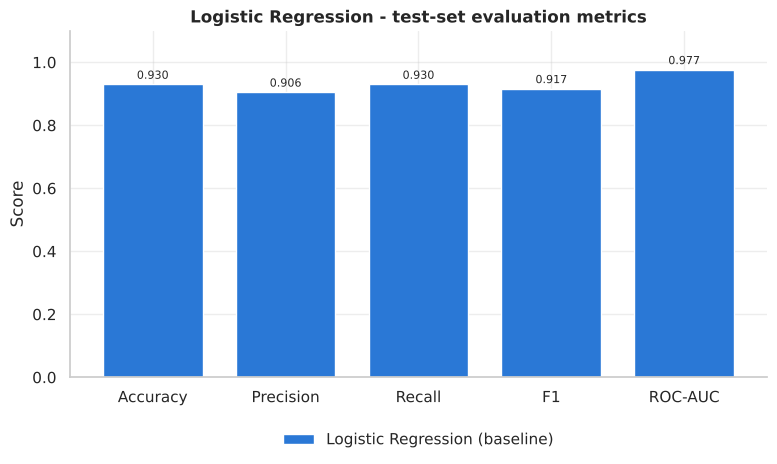

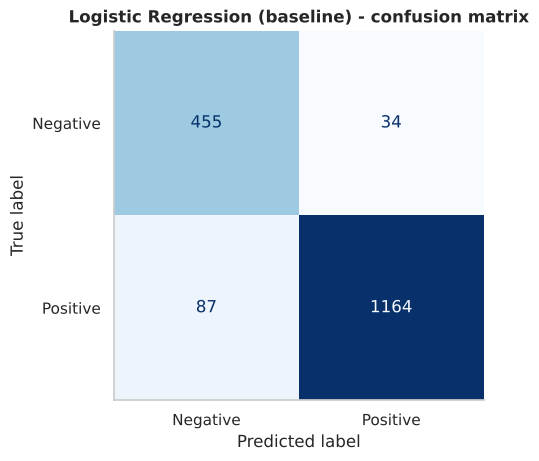

In [54]:
# Visualizing evaluation Metric Score chart
plot_scores({'Logistic Regression (baseline)': results['Logistic Regression (baseline)']}, 'Logistic Regression - test-set evaluation metrics', colors=(BLUE,))
plot_confusion(lr_base, 'Logistic Regression (baseline) - confusion matrix')

**Logistic Regression** is a linear classifier that learns a weight for every TF-IDF term and predicts the probability that a review is Positive. It is fast, works well on sparse text and its weights are easy to interpret, which makes it a strong baseline.

**Baseline performance (test set):** accuracy 0.930, macro precision 0.906, macro recall 0.930, macro F1 0.917, ROC-AUC 0.977. The model already separates positive from negative reviews very well.

#### 2. Cross- Validation & Hyperparameter Tuning

Baseline 5-fold CV macro-F1: 0.935 (+/- 0.006)


Best parameters: {'clf__C': 10, 'select__k': 3000} | best CV macro-F1: 0.945


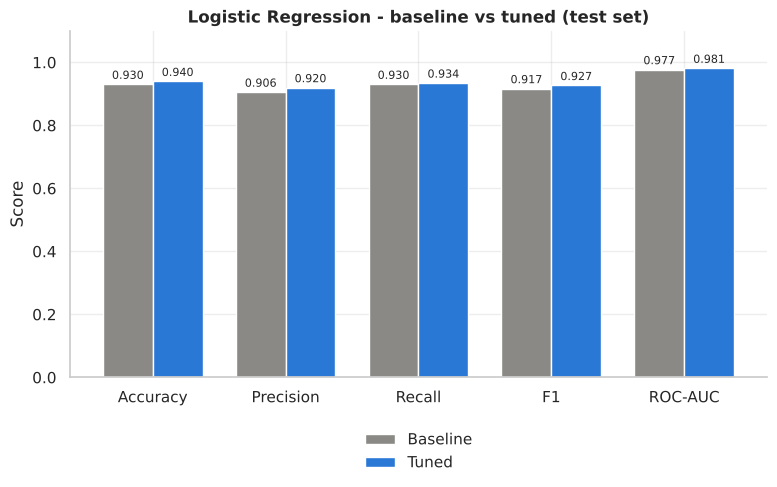

In [55]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
base_cv = cross_val_score(lr_base, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
print(f'Baseline 5-fold CV macro-F1: {base_cv.mean():.3f} (+/- {base_cv.std():.3f})')

# Fit the Algorithm
lr_grid = GridSearchCV(build_pipeline(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
                       param_grid={'clf__C': [0.1, 0.5, 1, 3, 10], 'select__k': [1500, 3000]},
                       cv=cv, scoring='f1_macro', n_jobs=-1)
lr_grid.fit(X_train, y_train)
lr_tuned = lr_grid.best_estimator_
print('Best parameters:', lr_grid.best_params_, '| best CV macro-F1:', round(lr_grid.best_score_, 3))

# Predict on the model
results['Logistic Regression (tuned)'] = get_scores(lr_tuned, X_test, y_test)
plot_scores({'Baseline': results['Logistic Regression (baseline)'], 'Tuned': results['Logistic Regression (tuned)']},
            'Logistic Regression - baseline vs tuned (test set)')

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV** with stratified 5-fold cross-validation, scored on macro-F1. The search space is small (regularisation strength C and number of selected features), so an exhaustive grid is affordable, and it guarantees the best combination in the grid is found. Macro-F1 was used as the score, because of the class imbalance.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**Yes.** Best parameters: C = 10 and 3,000 selected features, which raised the cross-validated macro-F1 from 0.935 to 0.945. On the test set: accuracy 0.930 to 0.940, macro precision 0.906 to 0.920, macro F1 0.917 to 0.927 and ROC-AUC 0.977 to 0.981. A weaker regularisation (C = 10) let the model use more of the informative terms.

### ML Model - 2

In [56]:
# ML Model - 2 Implementation (Linear Support Vector Machine)
# Fit the Algorithm
svm_base = build_pipeline(LinearSVC(class_weight='balanced', random_state=RANDOM_STATE))
svm_base.fit(X_train, y_train)

# Predict on the model
results['Linear SVM (baseline)'] = get_scores(svm_base, X_test, y_test)
print(pd.Series(results['Linear SVM (baseline)']).round(3).to_string())

Accuracy     0.940
Precision    0.921
Recall       0.934
F1           0.927
ROC-AUC      0.981


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

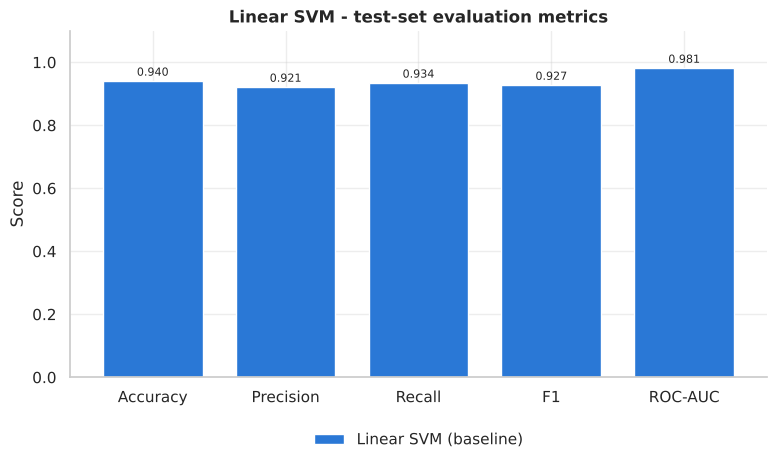

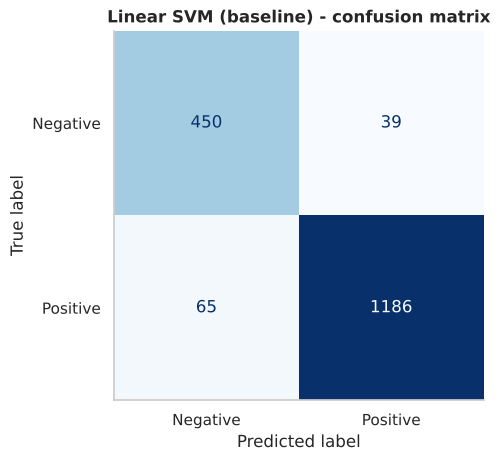

In [57]:
# Visualizing evaluation Metric Score chart
plot_scores({'Linear SVM (baseline)': results['Linear SVM (baseline)']}, 'Linear SVM - test-set evaluation metrics', colors=(BLUE,))
plot_confusion(svm_base, 'Linear SVM (baseline) - confusion matrix')

**Linear SVM** finds the straight boundary that separates positive from negative reviews with the widest margin. It is one of the strongest classical text classifiers, as high-dimensional sparse text is almost always linearly separable.

**Baseline performance (test set):** accuracy 0.940, macro precision 0.921, macro recall 0.934, macro F1 0.927, ROC-AUC 0.981: the best of the baselines.

#### 2. Cross- Validation & Hyperparameter Tuning

Baseline 5-fold CV macro-F1: 0.944 (+/- 0.007)


Best parameters: {'clf__C': 1, 'select__k': 3000} | best CV macro-F1: 0.944


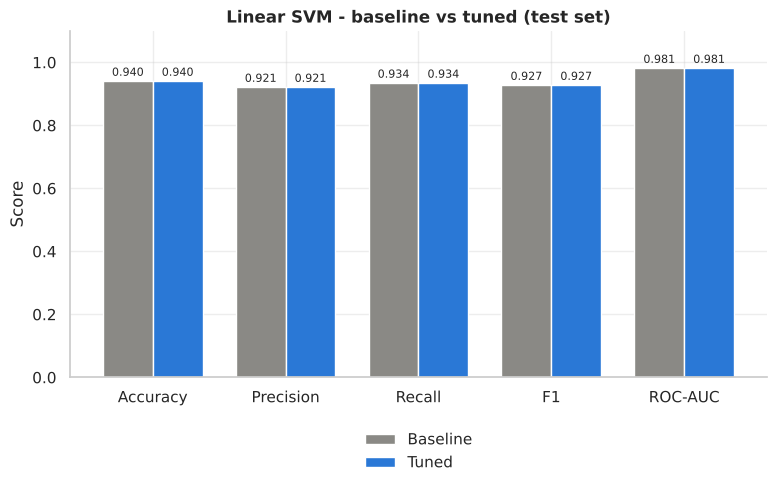

In [58]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
base_cv = cross_val_score(svm_base, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
print(f'Baseline 5-fold CV macro-F1: {base_cv.mean():.3f} (+/- {base_cv.std():.3f})')

# Fit the Algorithm
svm_grid = GridSearchCV(build_pipeline(LinearSVC(class_weight='balanced', random_state=RANDOM_STATE)),
                        param_grid={'clf__C': [0.03, 0.1, 0.3, 1], 'select__k': [1500, 3000]},
                        cv=cv, scoring='f1_macro', n_jobs=-1)
svm_grid.fit(X_train, y_train)
svm_tuned = svm_grid.best_estimator_
print('Best parameters:', svm_grid.best_params_, '| best CV macro-F1:', round(svm_grid.best_score_, 3))

# Predict on the model
results['Linear SVM (tuned)'] = get_scores(svm_tuned, X_test, y_test)
plot_scores({'Baseline': results['Linear SVM (baseline)'], 'Tuned': results['Linear SVM (tuned)']},
            'Linear SVM - baseline vs tuned (test set)')

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV** with stratified 5-fold cross-validation over C (0.03 to 1) and the number of selected features, again scored on macro-F1, for the same reasons as for Logistic Regression (a small grid, and an exhaustive search is cheap).

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**No meaningful improvement.** The best setting was C = 1, which is the default, so the tuned model is identical to the baseline (macro-F1 0.927, ROC-AUC 0.981 on the test set; cross-validated macro-F1 0.944). This is a useful result: the Linear SVM was already well configured, and the score chart for the tuned model is the same as the baseline chart.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

These apply to all models above, as Positive is the class of customers who are happy, and Negative the class of unhappy ones.

* **Accuracy (about 0.94):** 94 of 100 reviews are classified correctly. Good for a general quality check, but it can look good by simply favouring the majority class, so it is not used alone.
* **Precision (macro 0.92):** when the model flags a review as negative (or positive), it is right about 92% of the time. High precision avoids wasting support staff's time on false alarms and avoids wrongly praising a restaurant.
* **Recall (macro 0.93):** the model finds about 93% of the truly negative (and positive) reviews. For negatives, high recall means few unhappy customers are missed, which matters most because an unanswered complaint can lose the customer.
* **F1 (macro 0.927):** the balance of precision and recall across both classes; the main score for choosing the model, as the classes are imbalanced.
* **ROC-AUC (0.981):** the model ranks a random positive review above a random negative review 98% of the time, so a business can choose its own threshold, for example catching more complaints at the cost of more false alarms.

**Business impact:** automatic sentiment tagging of thousands of reviews lets Zomato and restaurant owners respond to unhappy customers quickly, track satisfaction over time, find recurring complaints and compare restaurants fairly, without reading each review by hand.

### ML Model - 3

In [59]:
# ML Model - 3 Implementation (Random Forest)
# Fit the Algorithm
rf_base = build_pipeline(RandomForestClassifier(n_estimators=150, class_weight='balanced_subsample',
                                                n_jobs=-1, random_state=RANDOM_STATE))
rf_base.fit(X_train, y_train)

# Predict on the model
results['Random Forest (baseline)'] = get_scores(rf_base, X_test, y_test)
print(pd.Series(results['Random Forest (baseline)']).round(3).to_string())

Accuracy     0.929
Precision    0.919
Recall       0.902
F1           0.910
ROC-AUC      0.969


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

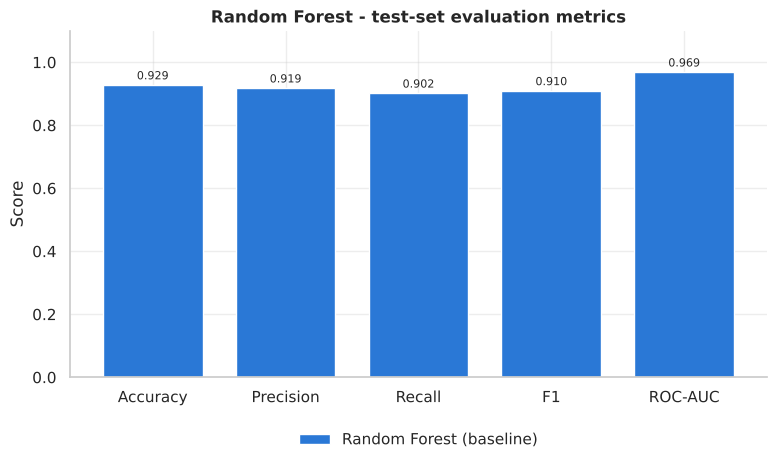

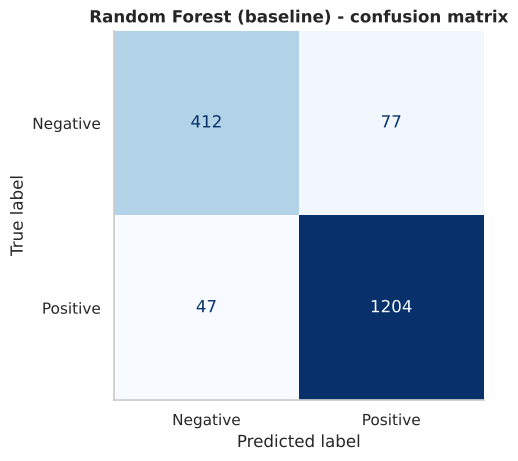

In [60]:
# Visualizing evaluation Metric Score chart
plot_scores({'Random Forest (baseline)': results['Random Forest (baseline)']}, 'Random Forest - test-set evaluation metrics', colors=(BLUE,))
plot_confusion(rf_base, 'Random Forest (baseline) - confusion matrix')

**Random Forest** builds hundreds of decision trees on random parts of the data and features and takes a vote. It can capture non-linear patterns and interactions between the numeric and text features, but on sparse text it is usually weaker than linear models.

**Baseline performance (test set):** accuracy 0.929, macro precision 0.919, macro recall 0.902, macro F1 0.910, ROC-AUC 0.970. It has the lowest recall of the three models, so it misses more of the minority class.

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters: {'select__k': 3000, 'clf__n_estimators': 250, 'clf__min_samples_leaf': 4, 'clf__max_depth': 80} | best CV macro-F1: 0.932


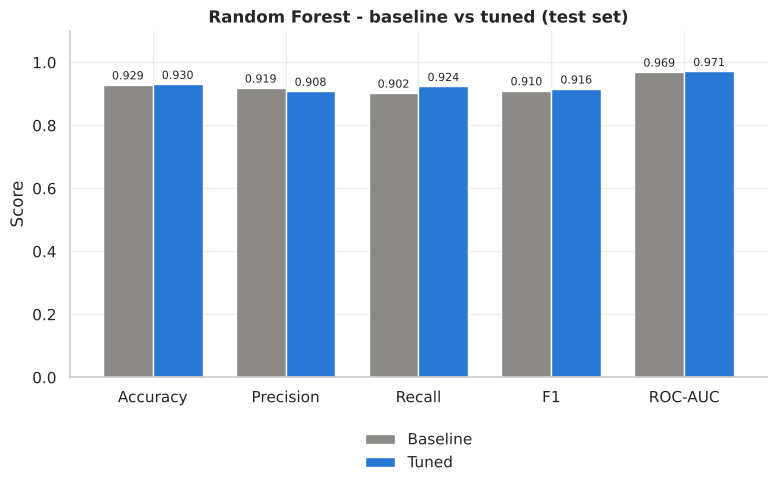

In [61]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Fit the Algorithm  (RandomizedSearchCV: a forest is slow to fit, so we sample 5 combinations instead of the full grid)
rf_search = RandomizedSearchCV(
    build_pipeline(RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE)),
    param_distributions={'clf__n_estimators': [150, 250], 'clf__max_depth': [None, 40, 80],
                         'clf__min_samples_leaf': [1, 2, 4], 'select__k': [1500, 3000]},
    n_iter=5, cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring='f1_macro', random_state=RANDOM_STATE)
rf_search.fit(X_train, y_train)
rf_tuned = rf_search.best_estimator_
print('Best parameters:', rf_search.best_params_, '| best CV macro-F1:', round(rf_search.best_score_, 3))

# Predict on the model
results['Random Forest (tuned)'] = get_scores(rf_tuned, X_test, y_test)
plot_scores({'Baseline': results['Random Forest (baseline)'], 'Tuned': results['Random Forest (tuned)']},
            'Random Forest - baseline vs tuned (test set)')

##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV** (5 sampled combinations, 3-fold stratified cross-validation, macro-F1). A forest is slow to train and the search space (number of trees, depth, minimum leaf size, selected features) is large, so random sampling finds a good setting in a fraction of the time that a full grid would take.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**Slight improvement.** Best parameters: 250 trees, maximum depth 80, minimum leaf size 4 and 3,000 features (cross-validated macro-F1 0.932). Test-set macro-F1 rose from 0.910 to 0.916, accuracy from 0.929 to 0.930 and ROC-AUC from 0.970 to 0.971. Limiting leaf size reduced overfitting, but the forest still trails the linear models.

### ML Model - 4 (Unsupervised) : Restaurant Segmentation with K-Means
The reviews tell us *what customers feel*; the metadata tells us *what each restaurant offers*. Clustering restaurants on price, cuisine mix and customer satisfaction gives business-friendly segments.

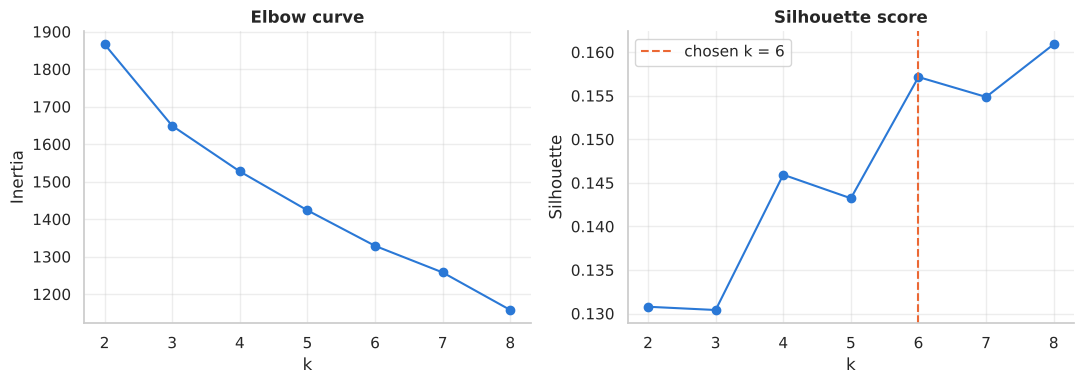

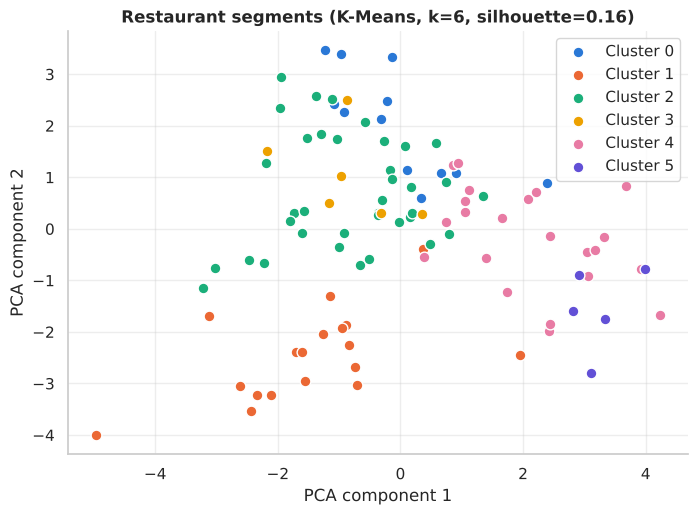

Chosen k = 6; silhouette scores for k=2..8: [0.131, 0.13, 0.146, 0.143, 0.157, 0.155, 0.161]


,Restaurants,Median_Cost,Avg_Rating,Pct_Positive,Top_Cuisines,Examples
Cluster,,,,,,
0,12,700.0,3.49,0.59,"North Indian, Chinese, South Indian","Beyond Flavours, Udipi's Upahar, Royal Spicy R..."
1,18,575.0,3.76,0.68,"Desserts, Cafe, Fast Food","B-Dubs, American Wild Wings, KS Bakers"
2,37,550.0,3.33,0.55,"North Indian, Chinese, Biryani","Paradise, NorFest - The Dhaba, Hyderabad Chefs"
3,6,875.0,3.40,0.58,"Mughlai, North Indian, Chinese","Hyderabadi Daawat, Khaan Saab, Aromas@11SIX"
4,22,1450.0,3.84,0.70,"North Indian, Continental, Italian","The Indi Grill, Zega - Sheraton Hyderabad Hote..."
5,5,1300.0,4.55,0.90,"Mediterranean, North Indian, Asian","AB's - Absolute Barbecues, 3B's - Buddies, Bar..."


In [62]:
# Restaurant-level feature table (one row per restaurant)
resto = meta_df.merge(rest_stats[['Restaurant', 'Avg_Rating', 'Pct_Positive', 'Reviews']],
                      left_on='Name', right_on='Restaurant').drop(columns='Restaurant').reset_index(drop=True)

# One-hot encode cuisines, keeping those served by at least 5 restaurants (rarer ones are noise)
cuisine_lists = resto['Cuisines'].str.split(', ')
frequent = cuisine_lists.explode().value_counts().loc[lambda s: s >= 5].index.tolist()
mlb = MultiLabelBinarizer(classes=frequent)
cuisine_matrix = pd.DataFrame(mlb.fit_transform(cuisine_lists.apply(lambda l: [c for c in l if c in frequent])),
                              columns=mlb.classes_, index=resto.index)

features = pd.concat([resto[['Cost', 'Avg_Rating', 'Pct_Positive']], cuisine_matrix], axis=1)
X_cluster = StandardScaler().fit_transform(features)

# Choose k with the silhouette score (higher = better separated clusters)
ks = range(2, 9)
sil, inertia = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
    sil.append(silhouette_score(X_cluster, km.labels_)); inertia.append(km.inertia_)
best_k = list(ks)[int(np.argmax(sil[1:5])) + 1]        # search k = 3..6 so segments stay interpretable

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(ks), inertia, marker='o', color=BLUE); axes[0].set(title='Elbow curve', xlabel='k', ylabel='Inertia')
axes[1].plot(list(ks), sil, marker='o', color=BLUE); axes[1].axvline(best_k, color=ORANGE, ls='--', label=f'chosen k = {best_k}')
axes[1].set(title='Silhouette score', xlabel='k', ylabel='Silhouette'); axes[1].legend()
plt.tight_layout(); plt.show()

# Final clustering + 2-D PCA view
km = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
resto['Cluster'] = km.labels_
coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_cluster)
palette = [BLUE, ORANGE, AQUA, YELLOW, '#e87ba4', '#6250d6']
plt.figure(figsize=(8, 5.5))
for c in range(best_k):
    m = resto['Cluster'] == c
    plt.scatter(coords[m, 0], coords[m, 1], s=60, color=palette[c], edgecolor='white', label=f'Cluster {c}')
plt.title(f'Restaurant segments (K-Means, k={best_k}, silhouette={silhouette_score(X_cluster, km.labels_):.2f})')
plt.xlabel('PCA component 1'); plt.ylabel('PCA component 2'); plt.legend(); plt.show()

print(f'Chosen k = {best_k}; silhouette scores for k=2..8:', [round(v, 3) for v in sil])
# Segment profiles
profile = resto.groupby('Cluster').agg(Restaurants=('Name', 'size'), Median_Cost=('Cost', 'median'),
                                       Avg_Rating=('Avg_Rating', 'mean'), Pct_Positive=('Pct_Positive', 'mean'))
profile['Top_Cuisines'] = [', '.join(resto.loc[resto['Cluster'] == c, 'Cuisines'].str.split(', ').explode()
                                     .value_counts().head(3).index) for c in profile.index]
profile['Examples'] = [', '.join(resto.loc[resto['Cluster'] == c].nlargest(3, 'Avg_Rating')['Name']) for c in profile.index]
profile.round(2)

**Model:** K-Means groups restaurants with similar cost, average rating, share of positive reviews and cuisine mix. The number of clusters was picked with the silhouette score (searching k = 3 to 6 to keep segments easy to explain), and k = 6 was best.

**Result (read the table above):**
* **Cluster 2 - Budget North Indian / Chinese / Biryani (37 restaurants, median ₹550, rating 3.33, 55% positive):** the largest group and the lowest rated: where improvement is needed most.
* **Cluster 1 - Cafés, desserts and fast food (18, ₹575, 3.76):** casual quick-bite places with decent satisfaction.
* **Cluster 0 - Mid-price family and South Indian restaurants (12, ₹700, 3.49).**
* **Cluster 3 - Mughlai / Hyderabadi (6, ₹875, 3.40).**
* **Cluster 4 - Premium casual and fine dining with Continental and Italian (22, ₹1,450, 3.84).**
* **Cluster 5 - Barbecue and Mediterranean buffet stars (5, ₹1,300, 4.55, 90% positive):** the benchmark group.

**Honest caveat:** the silhouette score is low (about 0.16 at k = 6), because only 100 restaurants are clustered and many share North Indian / Chinese menus. The segments are a descriptive guide, not sharply separated groups.

**Business impact:** Zomato can compare each restaurant with its true peers, target improvement programmes at the weakest segment, and use the star segment as a model of what customers love.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**Macro-averaged F1 (main), ROC-AUC, recall and precision**, with accuracy only as a reference. The business goal is to catch unhappy customers (Negative class) without ignoring happy ones, and Negative is the minority class (28%), so plain accuracy would be flattering. Macro-F1 balances precision and recall for both classes, recall shows how many complaints are found, precision shows how trustworthy the alerts are, and ROC-AUC shows how well the model ranks reviews independent of the decision threshold.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

,Accuracy,Precision,Recall,F1,ROC-AUC
Linear SVM (baseline),0.9402,0.9210,0.9341,0.9272,0.9812
Linear SVM (tuned),0.9402,0.9210,0.9341,0.9272,0.9812
Logistic Regression (tuned),0.9397,0.9198,0.9344,0.9266,0.9813
Logistic Regression (baseline),0.9305,0.9056,0.9305,0.9166,0.9769
Random Forest (tuned),0.9305,0.9085,0.9236,0.9156,0.9711
Random Forest (baseline),0.9287,0.9187,0.9025,0.9101,0.9695



Final model: Linear SVM (baseline)


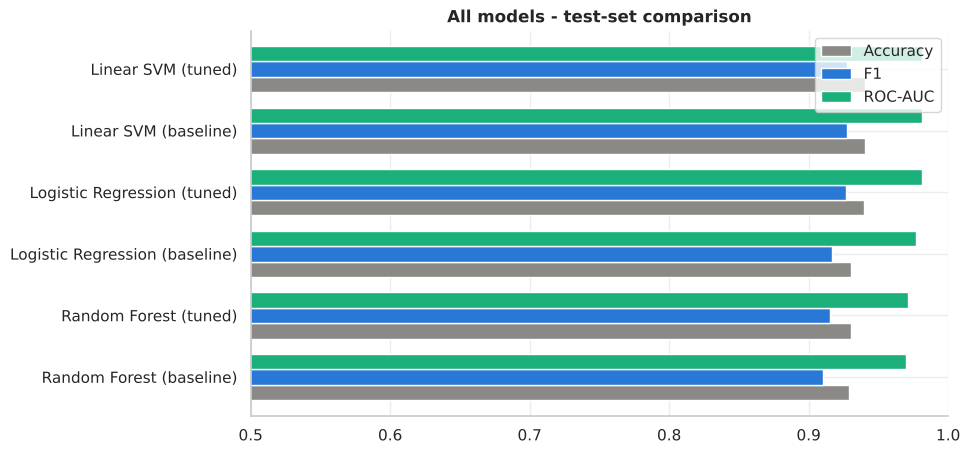

In [63]:
# Compare every model on the held-out test set
comparison = pd.DataFrame(results).T.sort_values(['F1', 'ROC-AUC'], ascending=False)   # ties broken by ROC-AUC
display(comparison.round(4))

best_name = comparison.index[0]
models = {'Logistic Regression (baseline)': lr_base, 'Logistic Regression (tuned)': lr_tuned,
          'Linear SVM (baseline)': svm_base, 'Linear SVM (tuned)': svm_tuned,
          'Random Forest (baseline)': rf_base, 'Random Forest (tuned)': rf_tuned}
best_model = models[best_name]
print('\nFinal model:', best_name)

ax = comparison[['Accuracy', 'F1', 'ROC-AUC']].sort_values('F1').plot(kind='barh', figsize=(9, 5), color=[GREY, BLUE, AQUA], width=0.75)
ax.set(title='All models - test-set comparison', xlim=(0.5, 1.0)); plt.show()

**Linear SVM.** It has the highest test macro-F1 (0.927) and a ROC-AUC of 0.981, and cross-validated scores are essentially equal (0.944 for SVM, 0.945 for tuned Logistic Regression). Tuned Logistic Regression is practically tied (F1 0.927, ROC-AUC 0.981), so the choice between them is a matter of use: the SVM is chosen by the selection rule, and Logistic Regression would be preferred if probability scores are needed. Random Forest was clearly behind (F1 0.916, lowest recall), and is also the slowest and largest. The Linear SVM is accurate, fast to train and predict, small to deploy and easy to explain.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

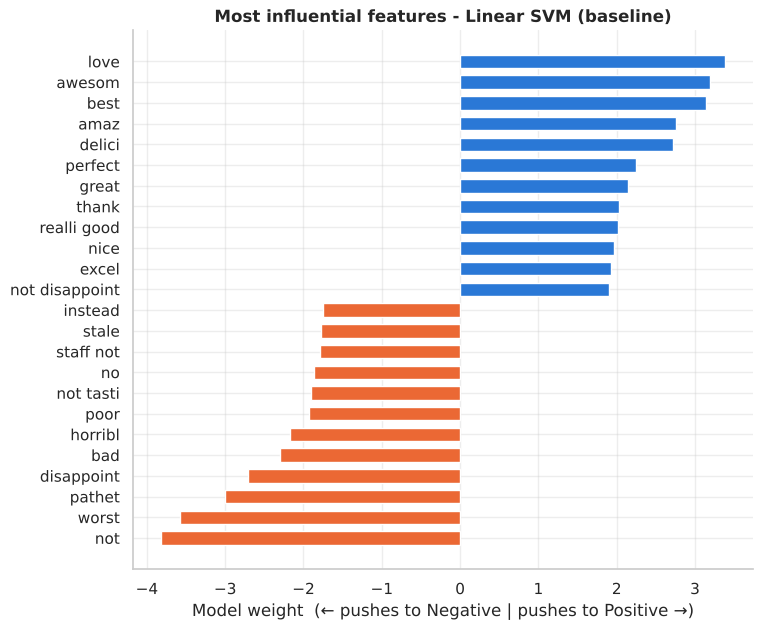

Stemmed words are shown (e.g. "delici" = delicious).
Strongest NEGATIVE words: not, worst, pathet, disappoint, bad, horribl, poor, not tasti, no, staff not
Strongest POSITIVE words: love, awesom, best, amaz, delici, perfect, great, thank, realli good, nice
Numeric feature weights: {'Cost': -0.02, 'Pictures': 0.96, 'Reviewer_Reviews_log': 0.52, 'Followers_log': -0.1, 'Review_Length_log': -0.04, 'Cuisine_Count': 0.09, 'Has_Collection': 0.06}


In [64]:
# Explainability: which words push a review towards Positive / Negative?
pre, select, clf = best_model.named_steps['pre'], best_model.named_steps['select'], best_model.named_steps['clf']
feature_names = pre.get_feature_names_out()[select.get_support()]
feature_names = np.array([n.split('__', 1)[1] for n in feature_names])

if hasattr(clf, 'coef_'):                                       # linear model -> signed weights
    weights = clf.coef_.ravel()
    top = pd.Series(weights, index=feature_names)
    shown = pd.concat([top.nsmallest(12), top.nlargest(12)]).sort_values()
    colors = [ORANGE if w < 0 else BLUE for w in shown.values]
    xlabel = 'Model weight  (← pushes to Negative | pushes to Positive →)'
else:                                                           # forest -> unsigned importances
    shown = pd.Series(clf.feature_importances_, index=feature_names).nlargest(24).sort_values()
    colors, xlabel = BLUE, 'Feature importance'

plt.figure(figsize=(8, 7))
plt.barh(shown.index, shown.values, color=colors, height=0.65)
plt.title(f'Most influential features - {best_name}'); plt.xlabel(xlabel); plt.show()
print('Stemmed words are shown (e.g. "delici" = delicious).')
if hasattr(clf, 'coef_'):
    print('Strongest NEGATIVE words:', ', '.join(top.nsmallest(10).index))
    print('Strongest POSITIVE words:', ', '.join(top.nlargest(10).index))
    print('Numeric feature weights:', {k: round(float(v), 2) for k, v in top.items() if k in NUM_FEATURES})

The final model is a **Linear SVM on TF-IDF features**: each term has a weight, and the sign says which class it supports. The chart above shows the weights, and the model's most important features are:
* **Pushing to Negative:** "not", "worst", "pathetic", "disappointing", "bad", "horrible", "poor", "not tasty".
* **Pushing to Positive:** "love", "awesome", "best", "amazing", "delicious", "perfect", "great", "thank you".
* **Numeric features:** reviews with pictures (+0.96) and reviews written by experienced reviewers (+0.52) are leaning positive, while cost and review length have almost no effect.

The explanation uses the model's own weights (stemmed words are shown, so "delici" means delicious). It is transparent, since the model is linear; SHAP or LIME could be added for per-review explanations.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [65]:
# Save the File
joblib.dump(best_model, 'zomato_sentiment_model.joblib')      # the whole pipeline: TF-IDF + scaler + selector + classifier
print(f'Saved "{best_name}" to zomato_sentiment_model.joblib')

Saved "Linear SVM (baseline)" to zomato_sentiment_model.joblib


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [66]:
# Load the File and predict unseen data.
loaded_model = joblib.load('zomato_sentiment_model.joblib')

new_reviews = pd.DataFrame({
    'Review': ['Amazing biryani, courteous staff and a lovely ambience. Totally worth the money!',
               "Very slow service, the food was cold and stale. I won't be coming back.",
               'Great buffet spread with so many starters, the desserts were fantastic.',
               'Overpriced and tasteless. Waited an hour and the waiter was rude.'],
    'Cost': [1300, 500, 1500, 1600], 'Pictures': [2, 0, 1, 0], 'Reviewer_Reviews': [25, 3, 60, 2],
    'Followers': [120, 1, 450, 0], 'Cuisine_Count': [4, 3, 5, 3], 'Has_Collection': [1, 0, 1, 1]})

# Build the same features the model was trained on
new_reviews[TEXT_COL] = new_reviews['Review'].apply(preprocess_text)
new_reviews['Review_Length'] = new_reviews['Review'].str.split().str.len()
for c in log_cols:
    new_reviews[c + '_log'] = np.log1p(new_reviews[c])

pred = loaded_model.predict(new_reviews[[TEXT_COL] + NUM_FEATURES])
for text, label in zip(new_reviews['Review'], pred):
    print(f"{'POSITIVE' if label == 1 else 'NEGATIVE'}  <-  {text}")
assert len(pred) == len(new_reviews)
print('\nSanity check passed - the saved model loads and predicts on unseen reviews.')

POSITIVE  <-  Amazing biryani, courteous staff and a lovely ambience. Totally worth the money!
NEGATIVE  <-  Very slow service, the food was cold and stale. I won't be coming back.
POSITIVE  <-  Great buffet spread with so many starters, the desserts were fantastic.
NEGATIVE  <-  Overpriced and tasteless. Waited an hour and the waiter was rude.

Sanity check passed - the saved model loads and predicts on unseen reviews.


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

The merged Zomato data (100 Hyderabad restaurants, 9,962 reviews after cleaning) shows that customer satisfaction is polarised (38.5% five-star, 17.4% one-star), that **price tier, cuisine, photos and Zomato collections** all go with higher ratings (all three hypothesis tests significant at 5%), and that no numeric feature alone predicts the rating: **what customers write is what matters most**.

A text pipeline (cleaning that keeps negations, TF-IDF unigrams and bigrams, chi-square selection) with Linear SVM and tuned Logistic Regression classifies reviews as Positive or Negative with about **94% accuracy, 0.927 macro-F1 and 0.981 ROC-AUC** on unseen data. Random Forest was weaker (F1 0.916). The model is saved with joblib and verified on new reviews.

K-Means grouped the restaurants into six segments; the biggest (37 restaurants, budget North Indian / Chinese / Biryani) is also the lowest-rated, while a small barbecue and Mediterranean group sets the benchmark (rating 4.55). The clusters are weakly separated (silhouette about 0.16), so they should be used as a guide.

**Recommendations:** (1) use the model to monitor negative reviews and alert restaurants in near real time; (2) focus improvement effort on budget and biryani/fast-food restaurants, which have the lowest satisfaction and the most customers; (3) encourage photo reviews and collection listings, which signal quality; (4) address recurring complaints about orders and service shown by the word analysis.

**Limitations and next steps:** labels come from star ratings (a review's text and stars can disagree), the data covers one city and mostly 2018-2019, and the sampling of 100 reviews per restaurant limits trend analysis. Next steps are transformer-based models (BERT), aspect-level sentiment (food / service / ambience) and deployment as a small API.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***